# EEG en conducción simulada + Stroop: potenciales relacionados a eventos y dinámica oscilatoria

**Proyecto:** [EEG_Human_Vehicle](https://github.com/Arielo00/EEG_Human_Vehicle) · **Participante:** P20 · **Sesión:** UTB001, corrida 2

Este notebook analiza la actividad cerebral de un participante que resuelve una tarea Stroop mientras
conduce en un simulador, comparando ensayos **congruentes** contra **incongruentes**. Lee directamente
el registro crudo de BCI2000 (`.dat`) y llega hasta la estadística; ya no depende de MATLAB.

### La tarea
- **Pantalla:** fondo blanco con el simulador de manejo en una ventana central. En cada ensayo aparecía, en uno
  de los cuatro puntos cardinales alrededor del simulador (elegido al azar), el nombre de un color escrito con
  tinta de un color.
- **Estímulos:** 16 combinaciones de palabra y tinta con cuatro colores (Y amarillo, B azul, R rojo, G verde):
  4 congruentes (`YY`, `BB`, `RR`, `GG`) y 12 incongruentes (`YB`, `RG`, …). La segunda letra es la tinta.
- **Ensayos:** 320 en orden aleatorio, 160 congruentes y 160 incongruentes. Cada estímulo permanece
  5 s en pantalla, con 1 a 2 s de pausa entre estímulos.
- **Respuesta:** al color de la tinta, con cuatro teclas del teclado numérico dispuestas en cruz (verde 8,
  rojo 4, azul 6, amarillo 2). El teclado estaba abajo y a la derecha del participante. Solo cuenta la primera
  pulsación tras cada estímulo.
- **Sesión:** una línea base de 5 min, la tarea de 35 min mientras conducía y otra línea base de 5 min.
- **Registro:** 16 canales con g.USBamp a 256 Hz; filtro del amplificador de 0.1 a 60 Hz y notch de 60 Hz.

> **Pendiente (autor):** añade aquí el escenario de conducción y el electrodo de referencia del registro.

### Qué pregunta responde
El efecto Stroop es el costo de resolver un conflicto: cuando la palabra y la tinta no coinciden, responder
toma más tiempo. En el EEG ese conflicto deja tres huellas bien documentadas, y este notebook las busca todas:

| Huella | Dónde | Cuándo | Qué se espera en incongruente |
|---|---|---|---|
| **N450** (negatividad de conflicto) | fronto-central | 350–500 ms | voltaje más negativo |
| **SP de conflicto** (positividad sostenida) | centro-parietal | 600–900 ms | voltaje más positivo |
| **Theta frontal medial** | Fz | 4–8 Hz, 300–700 ms | mayor potencia |

### Contenido
1. Configuración · 2. Canales y regiones de interés · 3. Carga y validación · 4. Conducta ·
5. Objetos MNE · 6. Preprocesamiento · 7. ERP global · 8. ERP por región · 9. Estadística ·
10. Lateralización · 11. Tiempo-frecuencia · 12. ERP ensayo por ensayo · 13. Fatiga · 14. Resumen

**Convenciones:** voltaje en µV con positivo hacia arriba; tiempo 0 = aparición del estímulo;
toda diferencia se calcula como **Incongruente − Congruente**.

## 1. Configuración
Todos los parámetros del análisis viven en esta celda. Nada más abajo tiene números "mágicos".

In [1]:
# ---------------------------------------------------------------- Datos
PARTICIPANT = "P20"
DATA_DIR = "/content/drive/MyDrive/P20_UTB001"
# Se usa el primer archivo que exista. El .dat (registro crudo de BCI2000) es la opción recomendada:
# permite filtrar la señal continua y recuperar la tecla presionada. El .mat (épocas exportadas por
# MATLAB_Prework/S03_GetEpochsRun2.m) queda como alternativa.
DATA_FILES = ["P20_UTBS001R02.dat", "P20_DataEpochs.mat"]
# Líneas base antes y después de la tarea (opcionales; solo se usan en la sección 13 y con el .dat).
BASELINE_FILES = {"antes": "P20_UTBS001R01.dat", "después": "P20_UTBS001R03.dat"}
N_BLOCKS = 4             # la tarea se presentó en 4 secuencias de 80 ensayos
DEMO_MODE = False        # True = genera datos SINTÉTICOS con la estructura del .mat (para probar sin datos)
OUT_DIR = "results"      # aquí se guardan figuras (.png) y tablas (.csv)
SEED = 20                # semilla para todo lo aleatorio (ICA, permutaciones)

# ---------------------------------------------------------------- Registro
SFREQ = 256.0            # Hz
EPOCH_TMIN, EPOCH_TMAX = -1.0, 5.0   # s; época larga alrededor de cada estímulo (igual que en MATLAB)
# Orden de canales del amplificador. MATLAB los etiqueta T5/T6 (nomenclatura 10-20 antigua);
# sus nombres actuales (10-10) son P7/P8 y son los que reconoce el montaje estándar de MNE.
CH_NAMES = ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8", "C3", "C4",
            "P7", "P3", "Pz", "P4", "P8", "O1", "O2"]
# Canales defectuosos de este participante (ver la evidencia en la sección 6.1). Se excluyen del ICA
# y de la estadística, y se interpolan solo para dibujar los mapas topográficos.
BAD_CHANNELS = ["Pz"]

# ---------------------------------------------------------------- Preprocesamiento
HP_FREQ, LP_FREQ = 0.1, 30.0   # Hz; pasa-banda para ERP (ver secciones 5 y 6 para el porqué)
ICA_ENABLED = True             # corrige la actividad ocular con ICA en lugar de tirar los ensayos
ICA_HP_FREQ = 1.0              # Hz; el ICA se ajusta sobre una copia filtrada a 1 Hz
ICA_VEOG_PROXY = ["Fp1", "Fp2"]   # no hay canales EOG: su promedio sigue los movimientos verticales y parpadeos
ICA_HEOG_PROXY = ("F8", "F7")     # y la diferencia F8 − F7 sigue los movimientos horizontales
ICA_CORR_THRESHOLD = 0.5       # |r| mínimo componente–referencia ocular para marcarlo como ocular
ICA_MIN_CONTRIBUTION_UV = 10.0 # µV mínimos que el componente debe aportar a la referencia (lo cerebral aporta menos)
ICA_MAX_EXCLUDE = 3            # tope de componentes a retirar
ICA_EXCLUDE_MANUAL = None      # p. ej. [0, 1] para imponer la selección tras revisar las topografías
ICA_SENSITIVITY_HP = [0.5, 2.0]   # Hz; ajustes alternativos del ICA para medir cuánto dependen de él los resultados (9.3)
REFERENCE = None               # None = conservar la referencia del registro; "average" = promedio común
ERP_TMIN, ERP_TMAX = -0.2, 1.0 # s; ventana de análisis ERP
BASELINE = (-0.2, 0.0)         # s; línea base pre-estímulo
REJECT_PTP_UV = 100.0          # µV pico a pico tras la limpieza; por encima se descarta el ensayo

# ---------------------------------------------------------------- Conducta
RT_VALID_RANGE = (0.15, 3.0)   # s; fuera de aquí = anticipación u omisión
REQUIRE_VALID_RT = True        # analizar solo ensayos con respuesta válida
REQUIRE_CORRECT = True         # y, si se conoce la tecla, solo ensayos correctos
# Solo para el .mat: S03_GetEpochsRun2.m calcula RT = muestra/fs - 0.5, pero la época empieza 1.0 s antes
# del estímulo. El RT real es RT_guardado - 0.5 s - 1 muestra (verificado contra el .dat: coincide en los
# 320 ensayos). Si se corrige el script de MATLAB, poner MAT_RT_CORRECTION = 0.0.
MAT_RT_CORRECTION = -(0.5 + 1.0 / SFREQ)

# ---------------------------------------------------------------- Regiones de interés (ROI)
# Ocho regiones que no se traslapan y cubren los 16 canales.
ROIS = {
    "Frontal izq. (FI)":   ["Fp1", "F7", "F3"],
    "Frontal medial (Fz)": ["Fz"],
    "Frontal der. (FD)":   ["Fp2", "F8", "F4"],
    "Central izq. (C3)":   ["C3"],
    "Central der. (C4)":   ["C4"],
    "Posterior izq. (PI)": ["P7", "P3", "O1"],
    "Parietal medial (Pz)": ["Pz"],
    "Posterior der. (PD)": ["P8", "P4", "O2"],
}
# Combinaciones del análisis original: cada cuadrante solo, con su electrodo de línea media y con su central.
ROIS_COMBINED = {
    "FI": ["Fp1", "F7", "F3"], "FI + Fz": ["Fp1", "F7", "F3", "Fz"], "FI + C3": ["Fp1", "F7", "F3", "C3"],
    "FD": ["Fp2", "F8", "F4"], "FD + Fz": ["Fp2", "F8", "F4", "Fz"], "FD + C4": ["Fp2", "F8", "F4", "C4"],
    "PI": ["P7", "P3", "O1"],  "PI + Pz": ["P7", "P3", "O1", "Pz"],  "PI + C3": ["P7", "P3", "O1", "C3"],
    "PD": ["P8", "P4", "O2"],  "PD + Pz": ["P8", "P4", "O2", "Pz"],  "PD + C4": ["P8", "P4", "O2", "C4"],
}

# ---------------------------------------------------------------- Ventanas temporales (definidas a priori)
WINDOWS = {
    "Visual temprano (100–200 ms)": (0.10, 0.20),
    "Conflicto N450/P3 (350–500 ms)": (0.35, 0.50),
    "SP tardío (600–900 ms)": (0.60, 0.90),
}

# ---------------------------------------------------------------- Estadística
N_PERMUTATIONS = 5000
ALPHA = 0.05

# ---------------------------------------------------------------- Tiempo-frecuencia
TFR_FMIN, TFR_FMAX = 4.0, 30.0
TFR_BASELINE = (-0.5, -0.2)    # s
THETA_BAND = (4.0, 8.0)        # Hz
THETA_WINDOW = (0.3, 0.7)      # s
TFR_CHANNELS = ["Fz", "C3", "C4", "Pz"]

# ---------------- Fatiga (sección 13, exploratoria)
ATTENTION_CHANNELS = ["P3", "P4"]      # respuesta parietal a cada estímulo
ATTENTION_WINDOW = (0.35, 0.60)        # s
FATIGUE_REGIONS = {"Frontal medial": ["F3", "Fz", "F4"], "Central": ["C3", "C4"],
                   "Posterior": ["P3", "P4", "P7", "P8", "O1", "O2"]}
FATIGUE_BANDS = {"theta": (4, 8), "alfa": (8, 13), "beta": (13, 30)}   # Hz
SLOW_BANDS = {"lenta (0.1–1 Hz)": (0.1, 1), "delta (1–4 Hz)": (1, 4), "theta (4–8 Hz)": (4, 8),
              "alfa (8–13 Hz)": (8, 13), "beta (13–30 Hz)": (13, 30)}

In [2]:
import importlib.util
import os
import re
import subprocess
import sys
import warnings

if importlib.util.find_spec("mne") is None:      # Colab no trae MNE instalado
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mne>=1.7"])

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy import signal, stats

assert tuple(int(v) for v in mne.__version__.split(".")[:2]) >= (1, 7), "Se requiere MNE >= 1.7"
mne.set_log_level("WARNING")
rng = np.random.default_rng(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
if DEMO_MODE:
    BAD_CHANNELS = []                            # los datos sintéticos no tienen canales defectuosos
GOOD_CHANNELS = [ch for ch in CH_NAMES if ch not in BAD_CHANNELS]

# Estilo de figuras: un color fijo por condición en todo el notebook.
C_CON, C_INC, C_INK, C_MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
COND_COLORS = {"Congruente": C_CON, "Incongruente": C_INC}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#d9d8d3", "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10,
})
DEMO_TAG = "  [DEMO: datos sintéticos]" if DEMO_MODE else ""


def save_fig(fig, name):
    """Guarda la figura en OUT_DIR y la devuelve."""
    fig.savefig(os.path.join(OUT_DIR, f"{PARTICIPANT}_{name}.png"))
    return fig


def make_montage():
    """Montaje 10-20 estándar. MNE 1.13 renombró 'standard_1020' a 'colin27_1020'; se acepta cualquiera."""
    for name in ("colin27_1020", "standard_1020"):
        try:
            return mne.channels.make_standard_montage(name)
        except ValueError:
            continue
    raise RuntimeError("No se encontró el montaje 10-20 en esta versión de MNE")


def good(*candidates):
    """Devuelve el primer canal de la lista que no esté marcado como defectuoso."""
    return next(ch for ch in candidates if ch not in BAD_CHANNELS)


def eog_proxies(ep):
    """Referencias oculares a partir del EEG, en voltios (ensayos × muestras): vertical y horizontal."""
    vertical = ep.get_data(picks=ICA_VEOG_PROXY).mean(axis=1)
    horizontal = ep.get_data(picks=[ICA_HEOG_PROXY[0]])[:, 0] - ep.get_data(picks=[ICA_HEOG_PROXY[1]])[:, 0]
    return vertical, horizontal


print(f"MNE {mne.__version__} · NumPy {np.__version__} · resultados en ./{OUT_DIR}/")

MNE 1.13.2 · NumPy 2.5.3 · resultados en ./results/


## 2. Canales y regiones de interés

### 2.1 Qué registra cada electrodo
El montaje tiene 16 electrodos del sistema internacional 10-20. La letra indica la región bajo el electrodo;
el número, el hemisferio (**impar = izquierdo**, **par = derecho**, **z = línea media**).

| Electrodos | Región | Qué aporta en esta tarea |
|---|---|---|
| **Fp1, Fp2** | Frontopolar (prefrontal anterior) | Control ejecutivo y atención sostenida. Son también los más cercanos a los ojos: registran parpadeos y movimientos verticales con gran amplitud, por lo que aquí sirven además como referencia ocular para limpiar artefactos. |
| **F7, F3, Fz, F4, F8** | Frontal | F3/F4 quedan sobre la corteza prefrontal dorsolateral (mantener la regla "responde al color"); F7/F8 sobre la frontal inferior (F7 cerca de áreas del lenguaje, F8 asociado a inhibición de respuestas) y, por su posición lateral, captan los movimientos oculares horizontales; **Fz** recoge la actividad frontal medial (monitoreo de conflicto, donde se originan la N450 y el theta frontal). |
| **C3, C4** | Central (sensoriomotora) | Quedan sobre el área de la mano de la corteza motora y somatosensorial. Como la respuesta es una tecla, reflejan la preparación y ejecución del movimiento, sobre todo en el hemisferio contrario a la mano que responde. |
| **P7, P3, Pz, P4, P8** | Parietal y temporo-parietal posterior | Integración sensorial y atención. **Pz** es el sitio clásico del P3b (evaluación del estímulo) y del SP de conflicto; P7/P8 (antes T5/T6) captan el procesamiento visual de alto nivel, y el izquierdo el de palabras escritas. |
| **O1, O2** | Occipital | Corteza visual: respuesta temprana al estímulo (P1, N1). |

**Una precaución de lectura:** un electrodo no mide solo la corteza que tiene debajo. El cráneo difumina
el campo eléctrico (conducción de volumen) y cada electrodo recibe una mezcla de fuentes cercanas y lejanas.
Las etiquetas de la tabla indican dónde es *máxima* cada actividad, no una localización exacta.

### 2.2 Por qué analizar electrodos en grupo
1. **Mejor relación señal/ruido.** Los electrodos vecinos ven la misma fuente cerebral, pero su ruido es en
   parte independiente. Promediar *n* canales conserva la señal común y reduce el ruido no compartido
   (hasta √n en el caso ideal), y eso se nota mucho con un solo participante.
2. **Menos comparaciones.** Probar 16 canales × cientos de muestras infla los falsos positivos.
   Ocho regiones definidas de antemano mantienen el análisis interpretable y corregible.
3. **Cada grupo responde una pregunta distinta**, que es lo que justifica las agrupaciones de este proyecto:

| Grupo | Electrodos | Por qué van juntos |
|---|---|---|
| **Frontal izquierda (FI)** | Fp1, F7, F3 | Red prefrontal izquierda. El Stroop es un conflicto *verbal*: aquí se espera el control sobre la lectura automática de la palabra. |
| **Frontal derecha (FD)** | Fp2, F8, F4 | Red prefrontal derecha, ligada a la inhibición de la respuesta incorrecta. Comparar FI contra FD dice si el control está lateralizado. |
| **Posterior izquierda (PI)** | P7, P3, O1 | Vía visual izquierda, del análisis visual temprano (O1) al reconocimiento de la palabra (P7) y la integración parietal (P3). |
| **Posterior derecha (PD)** | P8, P4, O2 | Su homóloga derecha: procesamiento del color y la forma, y atención espacial. Como los estímulos congruentes e incongruentes son visualmente equivalentes, la respuesta temprana de PI y PD **no debería diferir** entre condiciones: es el control negativo del análisis. |
| **Cuadrante + línea media** | FI/FD + **Fz**, PI/PD + **Pz** | Fz y Pz son donde las huellas del conflicto son máximas (N450 y theta en Fz; P3b y SP en Pz). Sumar el electrodo medial a su cuadrante mide si el efecto se extiende a la región lateral o queda confinado a la línea media. |
| **Cuadrante + central** | FI/PI + **C3**, FD/PD + **C4** | C3 y C4 son el final del recorrido: la orden motora. Frontal + central sigue el eje decisión → acción; posterior + central sigue el eje percepción → acción dentro de un mismo hemisferio. |

**Límites de las agrupaciones:**
- Al promediar regiones con polaridad opuesta (por ejemplo, una negatividad frontal con una positividad
  central) el efecto puede cancelarse. Por eso las ocho regiones separadas son el análisis principal y las
  combinaciones se presentan como análisis complementario (sección 8.2).
- FI y FD contienen los electrodos más expuestos a los ojos (Fp1/Fp2 y F7/F8). En una tarea con movimientos
  oculares, lo que se vea solo en esas regiones debe leerse junto con la sección 6.5.

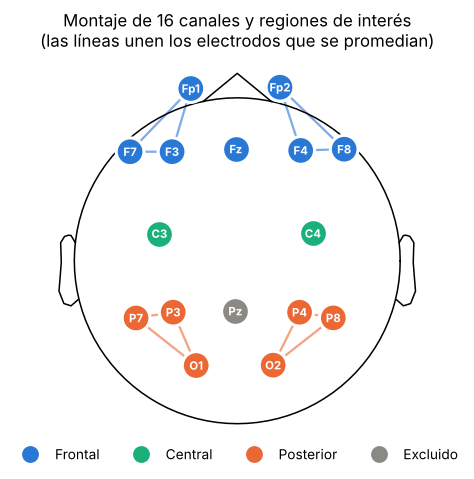

In [3]:
montage = make_montage()
info = mne.create_info(ch_names=CH_NAMES, sfreq=SFREQ, ch_types="eeg")
info.set_montage(montage)
info["description"] = f"Driving-Stroop {PARTICIPANT}"

# Comprobación: las ocho regiones cubren los 16 canales exactamente una vez.
_roi_chs = [ch for chs in ROIS.values() for ch in chs]
assert sorted(_roi_chs) == sorted(CH_NAMES), "Las ROI deben cubrir cada canal exactamente una vez"
# Regiones efectivas: sin los canales defectuosos (una región que se queda sin canales no se analiza).
ROIS_ACTIVE = {roi: [ch for ch in chs if ch in GOOD_CHANNELS] for roi, chs in ROIS.items()}
ROIS_ACTIVE = {roi: chs for roi, chs in ROIS_ACTIVE.items() if chs}

# Mapa de sensores coloreado por grupo de regiones.
_group_color = {"Frontal": "#2a78d6", "Central": "#1baf7a", "Posterior": "#eb6834"}
fig, ax = plt.subplots(figsize=(4.6, 4.8))
mne.viz.plot_sensors(info, show_names=False, axes=ax, show=False, pointsize=1)
_xy = np.array(ax.collections[0].get_offsets())            # posiciones 2D que dibujó MNE
ax.collections[0].set_visible(False)
for roi, chs in ROIS.items():
    group = "Frontal" if roi.startswith("Frontal") else "Central" if roi.startswith("Central") else "Posterior"
    idx = [CH_NAMES.index(ch) for ch in chs]
    colors = [_group_color[group] if ch in GOOD_CHANNELS else C_MUTED for ch in chs]
    ax.scatter(_xy[idx, 0], _xy[idx, 1], s=330, color=colors, edgecolor="white", linewidth=2, zorder=3)
    if len(idx) > 1:                                         # une los electrodos de una misma región
        loop = idx + [idx[0]]
        ax.plot(_xy[loop, 0], _xy[loop, 1], color=_group_color[group], lw=1.5, alpha=0.6, zorder=2)
for i, ch in enumerate(CH_NAMES):
    ax.text(_xy[i, 0], _xy[i, 1], ch, ha="center", va="center", fontsize=7.5, color="white", fontweight="bold", zorder=4)
handles = [plt.Line2D([], [], marker="o", ls="", ms=10, color=c, label=g) for g, c in _group_color.items()]
if BAD_CHANNELS:
    handles.append(plt.Line2D([], [], marker="o", ls="", ms=10, color=C_MUTED, label="Excluido"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=len(handles), fontsize=9)
ax.set_title("Montaje de 16 canales y regiones de interés\n(las líneas unen los electrodos que se promedian)")
ax.grid(False)
save_fig(fig, "01_montaje_roi")
plt.show()

## 3. Carga y validación de los datos
El registro `.dat` de BCI2000 contiene la señal continua de los 16 canales y, muestra a muestra, los
*estados* del experimento: cuándo aparece cada estímulo (`StimulusBegin`), cuál es (`StimulusCode`) y qué
tecla se presionó (`KeyDown`). El lector de abajo reproduce bit a bit lo que entrega `load_bcidat` en MATLAB
(verificado contra `P20_DataEpochs.mat`: diferencia máxima de 0 µV en los 320 ensayos).

In [4]:
def read_bci2000(path):
    """Lee un archivo BCI2000 .dat. Devuelve (señal en µV [muestras × canales], estados, parámetros)."""
    with open(path, "rb") as fh:
        first = fh.readline().decode("latin-1")
        header_len = int(re.search(r"HeaderLen=\s*(\d+)", first).group(1))
        n_ch = int(re.search(r"SourceCh=\s*(\d+)", first).group(1))
        state_len = int(re.search(r"StatevectorLen=\s*(\d+)", first).group(1))
        fmt = re.search(r"DataFormat=\s*(\w+)", first)
        dtype = np.dtype({"int16": "<i2", "int32": "<i4", "float32": "<f4"}[fmt.group(1) if fmt else "int16"])
        fh.seek(0)
        header = fh.read(header_len).decode("latin-1").split("\r\n")
        body = np.frombuffer(fh.read(), dtype=np.uint8)
    i_states = next(i for i, line in enumerate(header) if "State Vector Definition" in line)
    i_params = next(i for i, line in enumerate(header) if "Parameter Definition" in line)
    params = {}
    for line in header[i_params + 1:]:
        m = re.match(r"\S+\s+\S+\s+(\w+)=\s*(.*?)(\s+//.*)?$", line)
        if m:
            params[m.group(1)] = m.group(2)
    record = n_ch * dtype.itemsize + state_len                 # bytes por muestra: canales + vector de estados
    body = body[: (body.size // record) * record].reshape(-1, record)
    data = body[:, : n_ch * dtype.itemsize].copy().view(dtype).reshape(-1, n_ch).astype(float)
    gain = np.array(params["SourceChGain"].split()[1:1 + n_ch], dtype=float)
    offset = np.array(params["SourceChOffset"].split()[1:1 + n_ch], dtype=float)
    data = (data - offset) * gain                              # a µV
    bits = np.unpackbits(body[:, n_ch * dtype.itemsize:], axis=1, bitorder="little")
    states = {}
    for line in header[i_states + 1:i_params]:
        parts = line.split()
        if len(parts) == 5:                                    # nombre, longitud en bits, valor, byte, bit
            length, start = int(parts[1]), int(parts[3]) * 8 + int(parts[4])
            weights = 1 << np.arange(length, dtype=np.int64)
            states[parts[0]] = bits[:, start:start + length].astype(np.int64) @ weights
    return data, states, params


def load_bci2000_run(path):
    """Señal continua + tabla de ensayos (estímulo, condición, RT y tecla) a partir del .dat."""
    data, states, params = read_bci2000(path)
    sfreq = float(re.match(r"[\d.]+", params["SamplingRate"]).group())
    assert sfreq == SFREQ and data.shape[1] == len(CH_NAMES), "El archivo no coincide con SFREQ o CH_NAMES"
    onsets = np.flatnonzero(np.diff(np.r_[0, states["StimulusBegin"]]) == 1)       # muestra de cada estímulo
    codes = states["StimulusCode"][onsets]
    tokens = params["Stimuli"].split()                         # matriz: { filas } { columnas } valores...
    closing = [i for i, tok in enumerate(tokens) if tok == "}"]
    n_stimuli = closing[1] - closing[0] - 2
    labels = np.array(tokens[closing[1] + 1: closing[1] + 1 + n_stimuli])[codes - 1]   # p. ej. "YB"
    presses = np.flatnonzero(states["KeyDown"] > 0)
    limits = np.r_[onsets[1:], data.shape[0]]                  # la respuesta se busca hasta el siguiente estímulo
    first = [presses[(presses >= a) & (presses < b)][:1] for a, b in zip(onsets, limits)]
    trials = pd.DataFrame({
        "ensayo": np.arange(onsets.size),
        "condicion": np.where([lab[0] == lab[1] for lab in labels], "Congruente", "Incongruente"),
        "stimcode": codes, "estimulo": labels,
        "rt": [(f[0] - a) / sfreq if f.size else np.nan for f, a in zip(first, onsets)],
        "tecla": [int(states["KeyDown"][f[0]]) if f.size else 0 for f in first],
        "minuto": onsets / sfreq / 60,                          # momento del ensayo dentro de la corrida
    })
    return data, onsets, trials, params


def infer_accuracy(trials):
    """Comprueba con los datos el mapeo tecla → color y marca cada respuesta como correcta o no.

    El mapeo de la tarea es conocido (verde 8, rojo 4, azul 6, amarillo 2) y la respuesta correcta es la tinta,
    la segunda letra de la etiqueta. Aquí se verifica sin darlo por hecho, para que el notebook sirva con otros
    participantes: la tecla más frecuente en los congruentes da el mapeo, y en los incongruentes se comprueba
    qué letra de la etiqueta predice la tecla.
    """
    con = trials[trials["condicion"] == "Congruente"]
    key_of = con.groupby(con["estimulo"].str[0])["tecla"].agg(lambda s: s.mode().iat[0]).to_dict()
    inc = trials[trials["condicion"] == "Incongruente"]
    agreement = [np.mean(inc["tecla"] == inc["estimulo"].str[pos].map(key_of)) for pos in (0, 1)]
    target_pos = int(np.argmax(agreement))
    correct = (trials["tecla"] == trials["estimulo"].str[target_pos].map(key_of)).astype(float)
    return correct, key_of, target_pos, agreement


def simulate_stroop_mat(path, seed=0, n_trials=320, sfreq=256.0, tmin=-1.0, tmax=5.0):
    """Genera un .mat SINTÉTICO con la misma estructura que el de MATLAB (solo para DEMO_MODE).

    Incluye deriva lenta, ruido rosa, alfa posterior, parpadeos y efectos Stroop conocidos
    (RT, N450 frontal, SP parietal, theta frontal), de modo que sirve para verificar el pipeline.
    """
    g = np.random.default_rng(seed)
    n_times = int(round((tmax - tmin) * sfreq)) + 1
    t = tmin + np.arange(n_times) / sfreq
    pos = make_montage().get_positions()["ch_pos"]
    xyz = np.array([pos[ch] for ch in CH_NAMES])

    def topo(*centers, width=0.075):
        c = np.mean([pos[ch] for ch in centers], axis=0)
        return np.exp(-(np.linalg.norm(xyz - c, axis=1) / width) ** 2)

    def bump(mu, sd):
        return np.exp(-0.5 * ((t - mu) / sd) ** 2)

    cond = g.permutation(np.r_[np.ones(n_trials // 2), np.zeros(n_trials - n_trials // 2)]).astype(int)  # 1 = congruente
    stim = np.where(cond == 1, g.integers(1, 5, n_trials), g.integers(5, 17, n_trials))
    rt = np.exp(g.normal(np.where(cond == 1, np.log(0.62), np.log(0.72)), 0.22))
    rt_stored = np.round(rt * sfreq) / sfreq + 0.5 + 1.0 / sfreq          # reproduce el desfase de MATLAB
    rt_stored[g.random(n_trials) < 0.03] = np.inf                          # omisiones

    spatial_mix = np.exp(-(np.linalg.norm(xyz[:, None] - xyz[None], axis=2) / 0.07) ** 2)
    freqs = np.fft.rfftfreq(n_times, 1 / sfreq)
    shape_1f = np.r_[0, 1 / freqs[1:] ** 0.5]                 # espectro de potencia ~1/f (ruido rosa)
    X = np.zeros((n_trials, n_times, len(CH_NAMES)))
    for i in range(n_trials):
        noise = np.fft.irfft(np.fft.rfft(g.normal(size=(len(CH_NAMES), n_times)), axis=1) * shape_1f, n=n_times, axis=1)
        sig = 7.0 * (spatial_mix @ noise) / np.std(spatial_mix @ noise)
        sig += g.normal(0, 120, (len(CH_NAMES), 1)) + g.normal(0, 1, (len(CH_NAMES), 1)) * t      # offset y deriva
        sig += 6 * np.outer(topo("O1", "O2", width=0.09), np.sin(2 * np.pi * 10 * t + g.uniform(0, 2 * np.pi)))
        inc = cond[i] == 0
        k = g.normal(1, 0.25)                                                                       # variabilidad ensayo a ensayo
        sig += k * 4.0 * np.outer(topo("O1", "O2"), bump(0.11, 0.015))                              # P1
        sig -= k * 5.0 * np.outer(topo("P7", "P8", "O1", "O2", width=0.09), bump(0.17, 0.02))       # N1
        sig += k * 7.0 * np.outer(topo("Pz", width=0.09), bump(0.40, 0.08))                         # P3
        sig -= k * (4.5 if inc else 1.0) * np.outer(topo("Fz", width=0.08), bump(0.42, 0.05))       # N450
        sig += k * (4.0 if inc else 1.0) * np.outer(topo("Pz", width=0.08), bump(0.75, 0.12))       # SP
        sig -= 3.0 * np.outer(topo("C3", width=0.05), bump(rt[i] - 0.05, 0.06))                     # motor
        theta = np.sin(2 * np.pi * 6 * t + g.uniform(0, 2 * np.pi)) * bump(0.45, 0.15)
        sig += (5.0 if inc else 2.0) * np.outer(topo("Fz", width=0.07), theta)                      # theta frontal
        for _ in range(g.poisson(1.2)):                                                             # parpadeos
            sig += g.uniform(150, 280) * np.outer(topo("Fp1", "Fp2", width=0.06), bump(g.uniform(tmin, tmax), 0.07))
        X[i] = sig.T
    sio.savemat(path, {"epochs": X, "t": t[:, None], "epochtype": cond[:, None].astype(np.uint8),
                       "stimcode": stim[:, None].astype(float), "responsetime": rt_stored[:, None]})
    return path


def load_epochs_mat(path):
    """Lee el .mat de MATLAB y devuelve (X en µV con forma ensayos × canales × muestras, tabla de ensayos)."""
    mat = sio.loadmat(path)
    missing = {"epochs", "epochtype", "stimcode", "responsetime"} - set(mat)
    if missing:
        raise KeyError(f"Al archivo le faltan las variables: {sorted(missing)}")
    X = np.asarray(mat["epochs"], dtype=float)
    if X.ndim != 3 or X.shape[2] != len(CH_NAMES):
        raise ValueError(f"Se esperaba (ensayos, muestras, {len(CH_NAMES)} canales) y llegó {X.shape}")
    X = np.transpose(X, (0, 2, 1))                       # -> ensayos × canales × muestras
    stored = np.ravel(mat["responsetime"]).astype(float)
    trials = pd.DataFrame({
        "ensayo": np.arange(X.shape[0]),
        "condicion": np.where(np.ravel(mat["epochtype"]) == 1, "Congruente", "Incongruente"),
        "stimcode": np.ravel(mat["stimcode"]).astype(int),
        "estimulo": np.ravel(mat["stimcode"]).astype(int).astype(str),
        "rt": np.where(np.isfinite(stored), stored + MAT_RT_CORRECTION, np.nan),
        "tecla": 0,
        "minuto": np.nan,
    })
    return X, trials


# ---- Elegir y leer el archivo
if DEMO_MODE:
    data_path = simulate_stroop_mat(os.path.join(OUT_DIR, "DEMO_DataEpochs.mat"), seed=SEED)
    print("MODO DEMO: se usan datos SINTÉTICOS. Los resultados no son del participante.")
else:
    if "google.colab" in sys.modules and str(DATA_DIR).startswith("/content/drive"):
        from google.colab import drive
        drive.mount("/content/drive")
    data_path = next((os.path.join(DATA_DIR, f) for f in DATA_FILES if os.path.exists(os.path.join(DATA_DIR, f))), None)
    if data_path is None:
        raise FileNotFoundError(f"No encuentro ninguno de {DATA_FILES} en {DATA_DIR}. Corrige DATA_DIR "
                                "o usa DEMO_MODE = True para probar el notebook.")
INPUT_KIND = "dat" if data_path.lower().endswith(".dat") else "mat"
print(f"Archivo: {os.path.basename(data_path)} (modo {INPUT_KIND})")

if INPUT_KIND == "dat":
    signal_uv, onsets, trials, bci_params = load_bci2000_run(data_path)
    in_bounds = (onsets + int(EPOCH_TMIN * SFREQ) >= 0) & (onsets + int(EPOCH_TMAX * SFREQ) < signal_uv.shape[0])
    onsets, trials = onsets[in_bounds], trials[in_bounds].reset_index(drop=True)
    trials["correcta"], key_of_color, target_pos, agreement = infer_accuracy(trials)
    print(f"Registro continuo: {signal_uv.shape[0] / SFREQ / 60:.1f} min · {signal_uv.shape[1]} canales · "
          f"rango {signal_uv.min():.0f} a {signal_uv.max():.0f} µV")
    print("Parámetros del registro:", ", ".join(f"{k} = {bci_params[k].split()[0]}" for k in
          ("StimulusDuration", "ISIMinDuration", "ISIMaxDuration", "FilterHighPass", "FilterLowPass",
           "NotchHighPass", "NotchLowPass") if k in bci_params))
    print(f"Mapeo tecla → color (comprobado con los ensayos congruentes): {key_of_color}")
    print(f"En los incongruentes la tecla sigue a la {target_pos + 1}.ª letra de la etiqueta en el "
          f"{100 * agreement[target_pos]:.0f} % de los ensayos (a la otra letra, en el {100 * agreement[1 - target_pos]:.0f} %).")
else:
    X_uv, trials = load_epochs_mat(data_path)
    EPOCH_TMAX = EPOCH_TMIN + (X_uv.shape[2] - 1) / SFREQ
    trials["correcta"] = np.nan                              # el .mat no guarda la tecla: exactitud desconocida
    assert np.isfinite(X_uv).all(), "Hay valores NaN/inf en el EEG"
    print(f"Épocas: {X_uv.shape[0]} ensayos × {X_uv.shape[1]} canales × {X_uv.shape[2]} muestras "
          f"({EPOCH_TMIN:+.1f} a {EPOCH_TMAX:+.1f} s) · rango {X_uv.min():.0f} a {X_uv.max():.0f} µV")

n_trials = len(trials)
HAS_ACCURACY = bool(trials["correcta"].notna().any())
print(f"\nEnsayos: {n_trials}")
print(trials.groupby("condicion")["estimulo"].value_counts().unstack(fill_value=0).to_string())
assert trials["condicion"].nunique() == 2, "Se esperaban exactamente dos condiciones"

Archivo: P20_UTBS001R02.dat (modo dat)


Registro continuo: 35.1 min · 16 canales · rango -339 a 905 µV
Parámetros del registro: StimulusDuration = 5s, ISIMinDuration = 1s, ISIMaxDuration = 2s, FilterHighPass = 0.1, FilterLowPass = 60, NotchHighPass = 58, NotchLowPass = 62
Mapeo tecla → color (comprobado con los ensayos congruentes): {'B': 102, 'G': 104, 'R': 100, 'Y': 98}
En los incongruentes la tecla sigue a la 2.ª letra de la etiqueta en el 97 % de los ensayos (a la otra letra, en el 1 %).

Ensayos: 320
estimulo      BB  BG  BR  BY  GB  GG  GR  GY  RB  RG  RR  RY  YB  YG  YR  YY
condicion                                                                   
Congruente    40   0   0   0   0  40   0   0   0   0  40   0   0   0   0  40
Incongruente   0  12  16  12  16   0  12  12  16  12   0  12  12  12  16   0


## 4. Conducta: ¿hay efecto Stroop?
Antes de mirar el cerebro conviene confirmar que la tarea funcionó: el tiempo de reacción (RT) debe ser
mayor en los ensayos incongruentes. Si la conducta no muestra el efecto, los ERP son difíciles de interpretar.

El RT es el tiempo entre la aparición del estímulo y la primera tecla; si el participante volvía a presionar,
por diseño solo cuenta la primera pulsación. Con el `.dat` se conoce además qué tecla fue, así que el
análisis se hace solo sobre respuestas correctas.

              ensayos  respuesta_valida_pct  correctas_pct  analizables  rt_mediana_s
condicion                                                                            
Congruente        160                 100.0         99.375          159         0.977
Incongruente      160                 100.0         96.875          155         1.047 

RT mediano congruente (ms)                         976.56
RT mediano incongruente (ms)                      1046.88
Efecto Stroop, diferencia de medianas (ms)          70.31
t de Welch sobre log(RT)                             4.13
p (Welch)                                        4.65e-05
p (permutación)                                    0.0002
d de Cohen sobre log(RT)                             0.47
Exactitud congruente (%)                            99.38
Exactitud incongruente (%)                          96.88
p (Fisher, exactitud)                               0.214


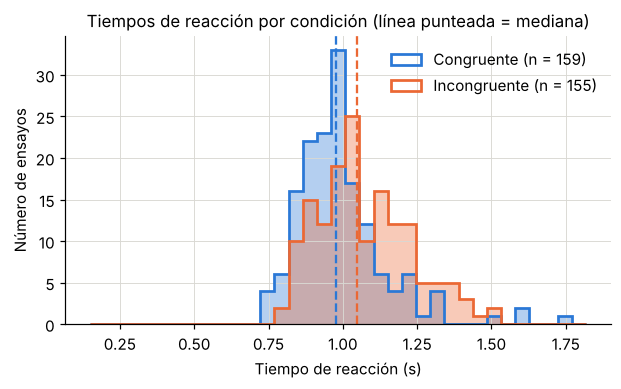

In [5]:
trials["rt_valido"] = trials["rt"].between(*RT_VALID_RANGE)       # NaN queda fuera
trials["analizable"] = trials["rt_valido"] & ((trials["correcta"] == 1) | (not HAS_ACCURACY) | (not REQUIRE_CORRECT))
trials["bloque"] = np.minimum(trials["ensayo"] // (n_trials // N_BLOCKS), N_BLOCKS - 1) + 1      # secuencia de la tarea
frac_valid = trials["rt_valido"].mean()
_median_rt = trials.loc[trials["rt_valido"], "rt"].median()
if not (0.25 <= _median_rt <= 2.0) or frac_valid < 0.6:
    warnings.warn(f"RT mediano = {_median_rt:.2f} s con {frac_valid:.0%} de ensayos válidos: revisa RT_VALID_RANGE "
                  "(y MAT_RT_CORRECTION si usas el .mat). El filtro por respuesta se desactiva.")
    REQUIRE_VALID_RT = False


def permutation_pvalue(a, b, n_perm=N_PERMUTATIONS):
    """p bilateral por permutación de etiquetas para la diferencia de medias (a - b)."""
    pooled = np.concatenate([a, b])
    observed = a.mean() - b.mean()
    shuffled = pooled[np.argsort(rng.random((n_perm, pooled.size)), axis=1)]
    null = shuffled[:, :a.size].mean(axis=1) - shuffled[:, a.size:].mean(axis=1)
    return (np.sum(np.abs(null) >= abs(observed)) + 1) / (n_perm + 1)


def cohens_d(a, b):
    """Tamaño de efecto (a - b) con desviación estándar combinada."""
    pooled_var = ((a.size - 1) * a.var(ddof=1) + (b.size - 1) * b.var(ddof=1)) / (a.size + b.size - 2)
    return (a.mean() - b.mean()) / np.sqrt(pooled_var)


_ok = trials[trials["analizable"]]
rt_con = _ok.loc[_ok["condicion"] == "Congruente", "rt"].to_numpy()
rt_inc = _ok.loc[_ok["condicion"] == "Incongruente", "rt"].to_numpy()
# El RT es asimétrico: se contrasta en escala logarítmica.
_t = stats.ttest_ind(np.log(rt_inc), np.log(rt_con), equal_var=False)
behavior = {
    "RT mediano congruente (ms)": 1000 * np.median(rt_con),
    "RT mediano incongruente (ms)": 1000 * np.median(rt_inc),
    "Efecto Stroop, diferencia de medianas (ms)": 1000 * (np.median(rt_inc) - np.median(rt_con)),
    "t de Welch sobre log(RT)": _t.statistic,
    "p (Welch)": _t.pvalue,
    "p (permutación)": permutation_pvalue(np.log(rt_inc), np.log(rt_con)),
    "d de Cohen sobre log(RT)": cohens_d(np.log(rt_inc), np.log(rt_con)),
}
summary_behavior = trials.groupby("condicion").agg(
    ensayos=("rt", "size"),
    respuesta_valida_pct=("rt_valido", lambda s: 100 * s.mean()),
    correctas_pct=("correcta", lambda s: 100 * s.mean()),
    analizables=("analizable", "sum"),
)
summary_behavior["rt_mediana_s"] = _ok.groupby("condicion")["rt"].median()
print(summary_behavior.round(3).to_string(), "\n")
if HAS_ACCURACY:
    _err = pd.crosstab(trials["condicion"], trials["correcta"] == 1).reindex(columns=[True, False], fill_value=0)
    _fisher = stats.fisher_exact(_err.to_numpy())
    behavior["Exactitud congruente (%)"] = 100 * trials.loc[trials["condicion"] == "Congruente", "correcta"].mean()
    behavior["Exactitud incongruente (%)"] = 100 * trials.loc[trials["condicion"] == "Incongruente", "correcta"].mean()
    behavior["p (Fisher, exactitud)"] = _fisher.pvalue
for k, v in behavior.items():
    print(f"{k:<46s} {v:>10.3g}" if k.startswith("p ") else f"{k:<46s} {v:>10.2f}")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
bins = np.linspace(RT_VALID_RANGE[0], min(RT_VALID_RANGE[1], np.percentile(_ok["rt"], 99.5)), 36)
for name, data in (("Congruente", rt_con), ("Incongruente", rt_inc)):
    ax.hist(data, bins=bins, histtype="stepfilled", alpha=0.35, color=COND_COLORS[name])
    ax.hist(data, bins=bins, histtype="step", lw=1.8, color=COND_COLORS[name], label=f"{name} (n = {data.size})")
    ax.axvline(np.median(data), color=COND_COLORS[name], ls="--", lw=1.5)
ax.set(xlabel="Tiempo de reacción (s)", ylabel="Número de ensayos",
       title=f"Tiempos de reacción por condición (línea punteada = mediana){DEMO_TAG}")
ax.legend()
save_fig(fig, "02_conducta_rt")
plt.show()

## 5. Objetos MNE
Se construyen tres versiones de las mismas épocas largas (−1 a 5 s): sin filtrar, filtradas para ERP
(0.1–30 Hz) y filtradas a 1 Hz para ajustar el ICA. Cada una lleva una tabla de metadatos por ensayo
(condición, estímulo, RT, tecla, exactitud), lo que permite seleccionar ensayos por consulta, por ejemplo
`epochs["rt < 0.9"]`.

- **Con el `.dat`** el filtro se aplica a la señal continua y después se cortan las épocas, que es lo
  correcto: el filtro no ve los bordes de cada ensayo.
- **Con el `.mat`** solo hay épocas ya cortadas, y a esas solo se les aplica el pasa-bajas de 30 Hz. El
  pasa-altas de 0.1 Hz ya lo hizo el amplificador sobre la señal continua; repetirlo sobre épocas de 6 s
  (o quitarles la tendencia lineal) deforma las ondas lentas. En P20, hacerlo cambia el ERP promedio en
  1.6 µV RMS respecto al filtrado continuo, mientras que el pasa-bajas solo lo reproduce con menos de 0.01 µV.

In [6]:
EVENT_ID = {"Congruente": 1, "Incongruente": 2}
_codes = np.where(trials["condicion"] == "Congruente", 1, 2)

if INPUT_KIND == "dat":
    raw = mne.io.RawArray(signal_uv.T * 1e-6, info.copy())   # MNE trabaja en voltios
    if REFERENCE == "average":
        raw.set_eeg_reference("average", projection=False)
    events = np.column_stack([onsets, np.zeros(n_trials, dtype=int), _codes])

    def cut(raw_like):
        ep = mne.Epochs(raw_like, events, EVENT_ID, tmin=EPOCH_TMIN, tmax=EPOCH_TMAX, baseline=None,
                        preload=True, metadata=trials.copy(), picks=CH_NAMES)
        assert len(ep) == n_trials, "Se perdieron épocas al cortar"
        return ep

    epochs_raw = cut(raw)
else:
    n_times = X_uv.shape[2]
    events = np.column_stack([np.arange(n_trials) * n_times + int(round(-EPOCH_TMIN * SFREQ)),
                              np.zeros(n_trials, dtype=int), _codes])
    epochs_raw = mne.EpochsArray(X_uv * 1e-6, info.copy(), events=events, event_id=EVENT_ID, tmin=EPOCH_TMIN,
                                 baseline=None, metadata=trials.copy())
    if REFERENCE == "average":
        epochs_raw.set_eeg_reference("average", projection=False)


def filtered_epochs(l_freq):
    """Épocas largas con pasa-banda de l_freq a LP_FREQ (l_freq = None: solo pasa-bajas)."""
    if INPUT_KIND == "dat":
        return cut(raw.copy().filter(l_freq, LP_FREQ, picks=CH_NAMES))        # filtra la señal continua
    return epochs_raw.copy().filter(l_freq, LP_FREQ, picks=CH_NAMES)          # filtra época por época


epochs_filt = filtered_epochs(HP_FREQ if INPUT_KIND == "dat" else None)
epochs_for_ica = filtered_epochs(ICA_HP_FREQ)
epochs_filt

<Epochs | 320 events (all good), -1 – 5 s (baseline off), ~60.1 MiB, data loaded, with metadata,
 'Congruente': 160
 'Incongruente': 160>

## 6. Preprocesamiento

| Paso | Qué se hace | Por qué |
|---|---|---|
| **Calidad por canal** | Se compara cada electrodo con sus vecinos | Un electrodo con mal contacto contamina los promedios y el ICA; se detecta porque deja de parecerse a los de alrededor. |
| **Filtro 0.1–30 Hz** | Pasa-banda de fase cero | Los potenciales evocados de interés (N450, P3, SP) son ondas lentas, con casi toda su energía por debajo de 4 Hz. El primer análisis filtró de 4 a 20 Hz porque buscaba los ritmos theta, alfa y beta: esa banda es adecuada para ritmos (sección 11), pero atenúa estos potenciales (sección 6.6). |
| **ICA ocular** | Se identifican y restan los componentes de parpadeo y de movimiento ocular | Con 16 canales cada ensayo cuenta. Corregir conserva ensayos que el rechazo por amplitud tiraría, y es indispensable cuando los ojos se mueven en casi todos los ensayos (sección 6.5). |
| **Recorte y línea base** | −200 a 1000 ms; se resta el promedio de −200 a 0 ms | Pone todos los ensayos en el mismo cero antes de promediar. |
| **Rechazo** | Fuera los ensayos con más de 100 µV pico a pico tras la limpieza | Elimina lo que el ICA no corrige (movimiento, músculo). |

### 6.1 Calidad por canal
Para cada electrodo se calcula su amplitud respecto a la de sus tres vecinos más cercanos y su correlación
con el promedio de ellos. Un electrodo sano se parece a sus vecinos, porque todos ven las mismas fuentes.
**Criterio de sospecha:** amplitud de al menos el doble **y** correlación menor que 0.7. Los frontopolares
pueden tener amplitud alta por la actividad ocular, pero conservan una correlación alta entre sí.

canal  amplitud (µV)     vecinos  amplitud / vecinos  correlación con vecinos  sospechoso  excluido
  Fp1          56.06 F7, Fp2, F3                1.46                     0.98       False     False
  Fp2          50.76 Fp1, F8, F4                1.62                     0.92       False     False
   F7          38.48 F3, Fp1, C3                1.53                     0.93       False     False
   F3          25.16 Fz, F7, Fp1                0.65                     0.97       False     False
   Fz          20.55 F3, F4, Fp1                0.82                     0.96       False     False
   F4          19.21 Fz, F8, Fp2                0.61                     0.90       False     False
   F8          31.34 F4, Fp2, C4                1.63                     0.49       False     False
   C3          14.96  P3, F3, P7                1.20                     0.94       False     False
   C4          14.94  P4, F4, P8                1.17                     0.90       False     False


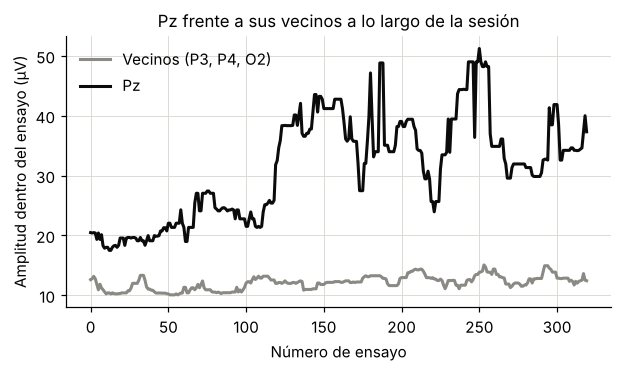

In [7]:
_x = epochs_filt.get_data(picks=CH_NAMES) * 1e6                         # ensayos × canales × muestras
_flat = _x.transpose(1, 0, 2).reshape(len(CH_NAMES), -1)
_pos = np.array([montage.get_positions()["ch_pos"][ch] for ch in CH_NAMES])
_dist = np.linalg.norm(_pos[:, None] - _pos[None], axis=2)
rows = []
for i, ch in enumerate(CH_NAMES):
    nn = np.argsort(_dist[i])[1:4]
    ratio = _flat[i].std() / np.median(_flat[nn].std(axis=1))
    corr = np.corrcoef(_flat[i], _flat[nn].mean(axis=0))[0, 1]
    rows.append({"canal": ch, "amplitud (µV)": _flat[i].std(), "vecinos": ", ".join(CH_NAMES[j] for j in nn),
                 "amplitud / vecinos": ratio, "correlación con vecinos": corr,
                 "sospechoso": bool(ratio >= 2 and corr < 0.7), "excluido": ch in BAD_CHANNELS})
channel_quality = pd.DataFrame(rows)
channel_quality.to_csv(os.path.join(OUT_DIR, f"{PARTICIPANT}_calidad_canales.csv"), index=False)
print(channel_quality.round(2).to_string(index=False))
_suspect = channel_quality.loc[channel_quality["sospechoso"], "canal"].tolist()
if sorted(_suspect) != sorted(BAD_CHANNELS):
    warnings.warn(f"Canales sospechosos según el criterio: {_suspect}; excluidos en la configuración: {BAD_CHANNELS}. "
                  "Revisa BAD_CHANNELS.")

# Evolución a lo largo de la sesión: amplitud por ensayo de cada canal excluido frente a sus vecinos.
if BAD_CHANNELS:
    fig, axes = plt.subplots(1, len(BAD_CHANNELS), figsize=(6.4 * len(BAD_CHANNELS), 3.2), squeeze=False)
    for ax, ch in zip(axes[0], BAD_CHANNELS):
        i = CH_NAMES.index(ch)
        nn = np.argsort(_dist[i])[1:4]
        smooth = lambda v: pd.Series(v).rolling(15, center=True, min_periods=1).median().to_numpy()
        ax.plot(smooth(_x[:, nn].std(axis=2).mean(axis=1)), color=C_MUTED, label=f"Vecinos ({', '.join(CH_NAMES[j] for j in nn)})")
        ax.plot(smooth(_x[:, i].std(axis=1)), color=C_INK, label=ch)
        ax.set(xlabel="Número de ensayo", ylabel="Amplitud dentro del ensayo (µV)",
               title=f"{ch} frente a sus vecinos a lo largo de la sesión")
        ax.legend()
    save_fig(fig, "03_calidad_canal_excluido")
    plt.show()

**¿Cansancio o electrodo?** La señal de Pz crece a lo largo de la sesión, y Pz está sobre una zona ligada a la
atención: cabe preguntarse si ese cambio refleja que el participante se iba cansando. Cuatro comprobaciones lo
deciden:
1. **Qué frecuencias crecen.** El cansancio cambia los ritmos theta y alfa; un electrodo que pierde contacto
   produce una deriva muy lenta, por debajo de 1 Hz.
2. **Qué pasa en los vecinos.** El cráneo difumina la actividad cerebral: una señal de ese tamaño bajo Pz tendría
   que verse también en P3 y P4, a pocos centímetros.
3. **Cuánto se parece a los vecinos** a lo largo de la sesión.
4. **Si acompaña a la conducta:** si reflejara cansancio, debería crecer cuando las respuestas se alargan.

Amplitud (µV) por banda y bloque, Pz frente al promedio de P3 y P4:
                    Pz                   vecinos                  
bloque               1     2     3     4       1     2     3     4
banda                                                             
lenta (0.1–1 Hz)  20.7  32.9  38.5  42.3    10.3  10.1  10.9  11.7
delta (1–4 Hz)     9.8  12.0  14.6  15.9     7.6   6.8   6.9   6.9
theta (4–8 Hz)     4.6   4.4   4.9   4.7     3.8   3.6   3.6   3.4
alfa (8–13 Hz)     3.6   3.8   3.8   3.8     3.1   3.2   3.2   3.1
beta (13–30 Hz)    2.9   3.1   3.1   3.1     2.6   2.8   2.8   2.7

Correlación por bloque:
 bloque  Pz con sus vecinos  P3 con P4
      1                0.59       0.81
      2                0.55       0.83
      3                0.49       0.80
      4                0.57       0.82

Correlación ensayo a ensayo entre amplitud y tiempo de reacción: Pz ρ = -0.11 (p = 0.042); vecinos ρ = +0.33 (p = 3.13e-09).


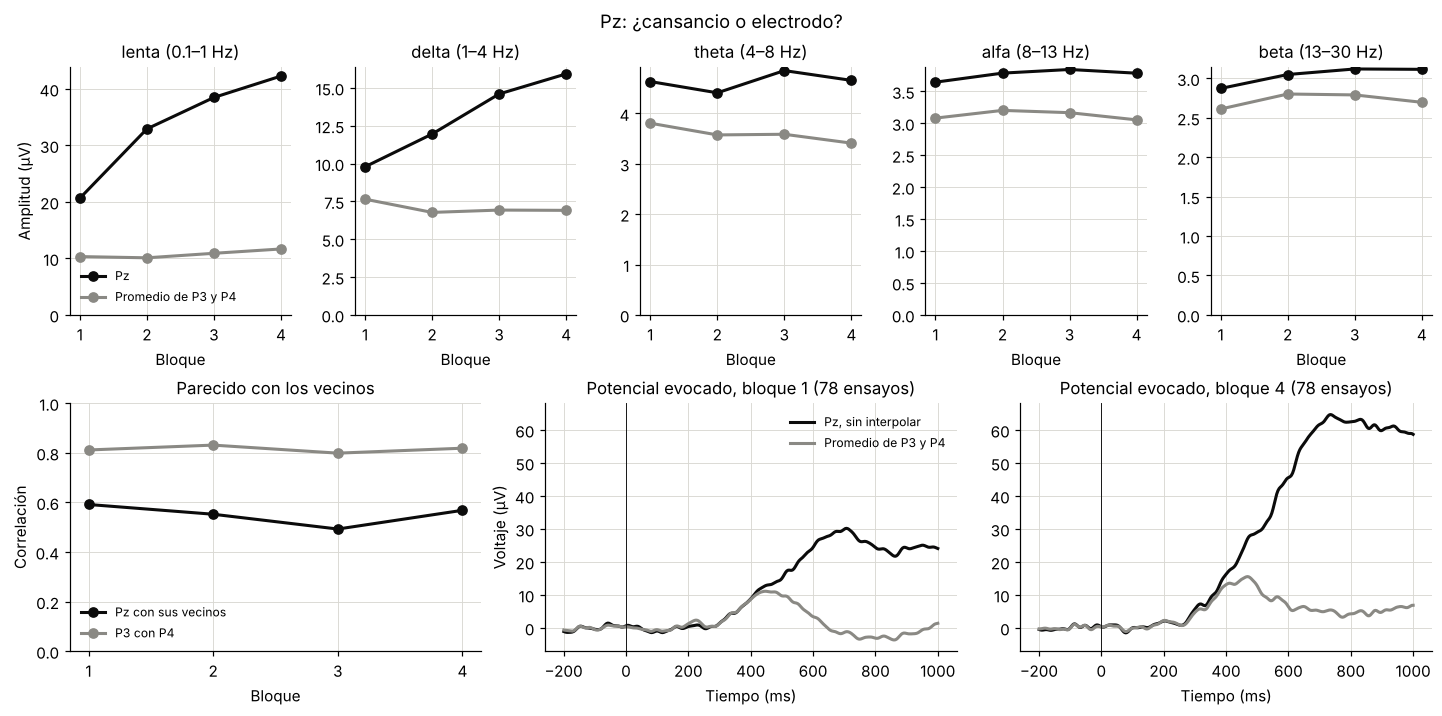

In [8]:
bad_channel_tests = {}
for ch in BAD_CHANNELS:
    i_bad = CH_NAMES.index(ch)
    nn = [CH_NAMES[j] for j in np.argsort(_dist[i_bad])[1:] if CH_NAMES[j] in GOOD_CHANNELS][:2]     # dos vecinos sanos
    correct = (trials["correcta"] == 1).to_numpy() if HAS_ACCURACY else trials["rt_valido"].to_numpy()
    win = epochs_filt.copy().crop(ERP_TMIN, ERP_TMAX)                       # aún sin interpolar
    amp_bad = win.get_data(picks=[ch])[:, 0].std(axis=1) * 1e6
    amp_nn = np.mean([win.get_data(picks=[c])[:, 0].std(axis=1) for c in nn], axis=0) * 1e6
    rho_bad = stats.spearmanr(amp_bad[correct], trials.loc[correct, "rt"])
    rho_nn = stats.spearmanr(amp_nn[correct], trials.loc[correct, "rt"])
    win.apply_baseline(BASELINE)
    erp_bad = win.get_data(picks=[ch])[:, 0] * 1e6
    erp_nn = np.mean([win.get_data(picks=[c])[:, 0] for c in nn], axis=0) * 1e6
    test = {"vecinos": nn, "rho_rt": (rho_bad.statistic, rho_bad.pvalue), "rho_rt_vecinos": (rho_nn.statistic, rho_nn.pvalue)}

    by_band, corr_rows = None, None
    if INPUT_KIND == "dat":                                                 # hace falta la señal continua
        spans = []
        for b in range(1, N_BLOCKS + 1):
            idx = trials.index[trials["bloque"] == b]
            spans.append((onsets[idx[0]] - int(SFREQ), onsets[idx[-1]] + int(6 * SFREQ)))
        rows = []
        for band, (lo, hi) in SLOW_BANDS.items():
            filt = raw.copy().filter(lo, hi, picks=[ch] + nn)
            y_bad = filt.get_data(picks=[ch])[0] * 1e6
            y_nn = [filt.get_data(picks=[c])[0] * 1e6 for c in nn]
            for b, (a, z) in enumerate(spans, 1):
                rows.append({"banda": band, "bloque": b, ch: y_bad[a:z].std(), "vecinos": np.mean([y[a:z].std() for y in y_nn])})
        by_band = pd.DataFrame(rows)
        filt = raw.copy().filter(HP_FREQ, LP_FREQ, picks=[ch] + nn)
        y_bad = filt.get_data(picks=[ch])[0]
        y_nn = [filt.get_data(picks=[c])[0] for c in nn]
        corr_rows = pd.DataFrame([{"bloque": b, f"{ch} con sus vecinos": np.corrcoef(y_bad[a:z], np.mean([y[a:z] for y in y_nn], axis=0))[0, 1],
                                   " con ".join(nn): np.corrcoef(y_nn[0][a:z], y_nn[1][a:z])[0, 1]} for b, (a, z) in enumerate(spans, 1)])
        print(f"Amplitud (µV) por banda y bloque, {ch} frente al promedio de {' y '.join(nn)}:")
        print(by_band.pivot(index="banda", columns="bloque", values=[ch, "vecinos"]).loc[list(SLOW_BANDS)].round(1).to_string())
        print("\nCorrelación por bloque:")
        print(corr_rows.round(2).to_string(index=False))
        by_band.to_csv(os.path.join(OUT_DIR, f"{PARTICIPANT}_{ch}_bandas_por_bloque.csv"), index=False)
    print(f"\nCorrelación ensayo a ensayo entre amplitud y tiempo de reacción: {ch} ρ = {rho_bad.statistic:+.2f} "
          f"(p = {rho_bad.pvalue:.3f}); vecinos ρ = {rho_nn.statistic:+.2f} (p = {rho_nn.pvalue:.3g}).")
    test.update(por_banda=by_band, correlacion=corr_rows)
    bad_channel_tests[ch] = test

    # Figura: bandas por bloque (arriba) y el canal tal cual frente a sus vecinos (abajo)
    first, last = trials["bloque"].min(), trials["bloque"].max()
    n_top = len(SLOW_BANDS) if by_band is not None else 0
    fig = plt.figure(figsize=(13, 6.4 if n_top else 3.4), layout="constrained")
    gs = fig.add_gridspec(2 if n_top else 1, 15)
    if n_top:
        for k, band in enumerate(SLOW_BANDS):
            ax = fig.add_subplot(gs[0, 3 * k:3 * k + 3])
            sub = by_band[by_band["banda"] == band]
            ax.plot(sub["bloque"], sub[ch], "o-", color=C_INK, label=ch)
            ax.plot(sub["bloque"], sub["vecinos"], "o-", color=C_MUTED, label=f"Promedio de {' y '.join(nn)}")
            ax.set(title=band, xlabel="Bloque", xticks=range(1, N_BLOCKS + 1), ylim=(0, None))
            if k == 0:
                ax.set_ylabel("Amplitud (µV)")
                ax.legend(fontsize=8)
        ax = fig.add_subplot(gs[1, 0:5])
        for col, color in zip(corr_rows.columns[1:], (C_INK, C_MUTED)):
            ax.plot(corr_rows["bloque"], corr_rows[col], "o-", color=color, label=col)
        ax.set(title="Parecido con los vecinos", xlabel="Bloque", ylabel="Correlación", xticks=range(1, N_BLOCKS + 1), ylim=(0, 1))
        ax.legend(fontsize=8, loc="lower left")
    row, cols = (1, (slice(5, 10), slice(10, 15))) if n_top else (0, (slice(0, 7), slice(8, 15)))
    shared = None
    for block, col in zip((first, last), cols):
        ax = fig.add_subplot(gs[row, col], sharey=shared)
        shared = shared or ax
        sel = correct & (trials["bloque"] == block).to_numpy()
        ax.plot(win.times * 1000, erp_bad[sel].mean(axis=0), color=C_INK, label=f"{ch}, sin interpolar")
        ax.plot(win.times * 1000, erp_nn[sel].mean(axis=0), color=C_MUTED, label=f"Promedio de {' y '.join(nn)}")
        ax.axvline(0, color=C_INK, lw=0.6)
        ax.set(title=f"Potencial evocado, bloque {block} ({int(sel.sum())} ensayos)", xlabel="Tiempo (ms)")
        if block == first:
            ax.set_ylabel("Voltaje (µV)")
            ax.legend(fontsize=8)
    fig.suptitle(f"{ch}: ¿cansancio o electrodo?{DEMO_TAG}")
    save_fig(fig, f"03b_{ch}_cansancio_o_electrodo")
    plt.show()

**Cómo leerlo.** Si lo que crece es la banda lenta y los ritmos theta y alfa no cambian, si los vecinos no se
mueven en ninguna banda, si el canal se parece poco a ellos durante toda la sesión y si su amplitud no aumenta
con el tiempo de reacción, el patrón es el de un electrodo que pierde contacto, no el de un cerebro que se
cansa. En ese caso el canal queda fuera de la estadística, y la pregunta sobre el cansancio se responde con los
electrodos sanos en la sección 13.

### 6.2 ICA para la actividad ocular
No hay canales de electrooculograma, pero los electrodos frontales hacen ese trabajo: el promedio de
Fp1 y Fp2 sigue los parpadeos y los movimientos verticales, y la diferencia F8 − F7 sigue los horizontales.
Un componente independiente se retira si cumple tres condiciones con alguna de las dos referencias:
1. su señal se correlaciona con ella (|r| ≥ 0.5);
2. le aporta al menos 10 µV, porque la actividad ocular es de decenas a cientos de µV y la cerebral no;
3. su mapa tiene la forma que produce un ojo al moverse: mismo signo en Fp1 y Fp2 para lo vertical,
   signo opuesto en F7 y F8 para lo horizontal.

Las condiciones 2 y 3 evitan retirar actividad cerebral frontal que casualmente se parezca a una referencia.

In [9]:
def fit_ocular_ica(fit_epochs):
    """Ajusta el ICA y marca los componentes oculares. Devuelve (ica, tabla de criterios por componente)."""
    ica_ = mne.preprocessing.ICA(n_components=len(GOOD_CHANNELS) - 1, method="fastica", random_state=SEED, max_iter="auto")
    ica_.fit(fit_epochs, picks=GOOD_CHANNELS)
    sources = ica_.get_sources(fit_epochs).get_data()                      # ensayos × componentes × muestras
    sources = sources.transpose(1, 0, 2).reshape(ica_.n_components_, -1)
    weights = pd.DataFrame(ica_.get_components(), index=ica_.ch_names)     # mapa de cada componente
    proxies = dict(zip(("vertical", "horizontal"), (p.ravel() for p in eog_proxies(fit_epochs))))
    # Forma esperada del mapa: mismo signo en Fp1 y Fp2 (vertical); signo opuesto en F8 y F7 (horizontal).
    shape_ok = {"vertical": np.sign(weights.loc[ICA_VEOG_PROXY[0]]) == np.sign(weights.loc[ICA_VEOG_PROXY[1]]),
                "horizontal": np.sign(weights.loc[ICA_HEOG_PROXY[0]]) != np.sign(weights.loc[ICA_HEOG_PROXY[1]])}
    table = pd.DataFrame(index=pd.RangeIndex(ica_.n_components_, name="componente"))
    score = np.zeros(ica_.n_components_)
    for axis_name, proxy in proxies.items():
        r = np.array([abs(np.corrcoef(src, proxy)[0, 1]) for src in sources])
        contribution = r * proxy.std() * 1e6                               # µV que el componente aporta a la referencia
        table[f"r {axis_name}"] = r
        table[f"aporte {axis_name} (µV)"] = contribution
        passes = (r >= ICA_CORR_THRESHOLD) & (contribution >= ICA_MIN_CONTRIBUTION_UV) & shape_ok[axis_name].to_numpy()
        score = np.maximum(score, np.where(passes, r, 0.0))
    table["ocular"] = score > 0
    ranked = np.argsort(-score)
    ica_.exclude = sorted(int(c) for c in ranked[:ICA_MAX_EXCLUDE] if score[c] > 0)
    return ica_, table.loc[np.argsort(-table[["r vertical", "r horizontal"]].max(axis=1).to_numpy())]


ica_excluded = []
if ICA_ENABLED:
    ica, eog_corr = fit_ocular_ica(epochs_for_ica)
    if ICA_EXCLUDE_MANUAL is not None:
        ica.exclude = list(ICA_EXCLUDE_MANUAL)
    ica_excluded = list(ica.exclude)
    epochs_clean = ica.apply(epochs_filt.copy())
    print("Criterios oculares por componente (los seis con mayor correlación):")
    print(eog_corr.head(6).round(2).to_string())
    print(f"\nComponentes retirados: {ica_excluded if ica_excluded else 'ninguno'}")
else:
    epochs_clean = epochs_filt.copy()

# Los canales defectuosos se interpolan a partir de sus vecinos (solo para los mapas; no entran a la estadística).
if BAD_CHANNELS:
    for ep in (epochs_clean, epochs_filt):
        ep.info["bads"] = list(BAD_CHANNELS)
        ep.interpolate_bads(reset_bads=True)

Criterios oculares por componente (los seis con mayor correlación):
            r vertical  aporte vertical (µV)  r horizontal  aporte horizontal (µV)  ocular
componente                                                                                
1                 0.57                 25.66          0.81                   29.03    True
0                 0.79                 35.21          0.14                    5.19    True
2                 0.16                  7.06          0.54                   19.38    True
9                 0.02                  0.78          0.13                    4.80   False
7                 0.07                  3.06          0.11                    4.11   False
5                 0.09                  4.10          0.07                    2.56   False

Componentes retirados: [0, 1, 2]


**Revisa esta figura antes de seguir.** Un componente de parpadeo tiene una topografía concentrada en la
frente (Fp1/Fp2) que decae hacia atrás; uno de movimiento horizontal tiene signos opuestos en F7 y F8.
Si un componente marcado no se ve así, o si falta alguno evidente, fija la selección en
`ICA_EXCLUDE_MANUAL` (sección 1) y vuelve a ejecutar.

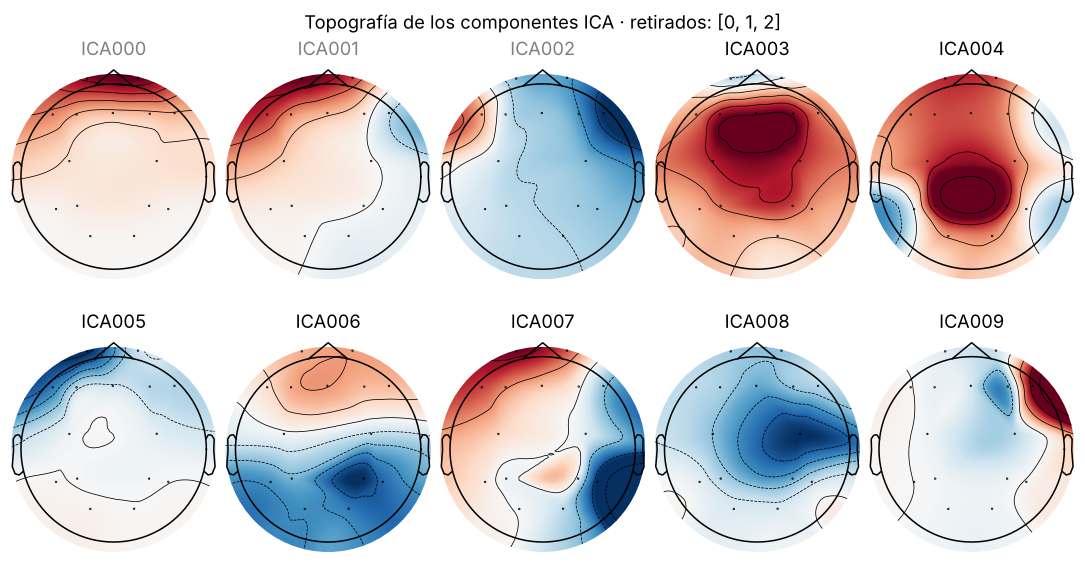

In [10]:
if ICA_ENABLED:
    figs = ica.plot_components(picks=range(min(10, ica.n_components_)), show=False)
    fig = figs[0] if isinstance(figs, list) else figs
    fig.suptitle(f"Topografía de los componentes ICA · retirados: {ica_excluded if ica_excluded else 'ninguno'}{DEMO_TAG}",
                 y=1.04, fontsize=12)
    save_fig(fig, "04_ica_componentes")
    plt.show()

### 6.3 Recorte, línea base y rechazo

In [11]:
epochs_erp_all = epochs_clean.copy().crop(ERP_TMIN, ERP_TMAX).apply_baseline(BASELINE)
epochs_noica_all = epochs_filt.copy().crop(ERP_TMIN, ERP_TMAX).apply_baseline(BASELINE)   # misma señal sin ICA
ptp_uv = np.ptp(epochs_erp_all.get_data(picks=CH_NAMES), axis=2) * 1e6       # ensayos × canales
bad_amplitude = (ptp_uv > REJECT_PTP_UV).any(axis=1)
bad_response = ~trials["analizable"].to_numpy() if REQUIRE_VALID_RT else np.zeros(n_trials, dtype=bool)
keep = ~(bad_amplitude | bad_response)

epochs = epochs_erp_all[keep]            # épocas ERP limpias: base de las secciones 7 a 10 y 12
epochs_noica = epochs_noica_all[keep]    # mismas épocas sin corrección ocular: para medir cuánto se retiró
epochs_long = epochs_clean[keep]         # mismas épocas completas (-1 a 5 s): base de la sección 11
md = epochs.metadata.reset_index(drop=True)
is_con = (md["condicion"] == "Congruente").to_numpy()
is_inc = ~is_con
times_ms = epochs.times * 1000

report = pd.DataFrame({
    "iniciales": trials["condicion"].value_counts(),
    "rechazo por amplitud": trials.loc[bad_amplitude, "condicion"].value_counts(),
    "respuesta inválida o incorrecta": trials.loc[bad_response & ~bad_amplitude, "condicion"].value_counts(),
    "conservados": md["condicion"].value_counts(),
}).fillna(0).astype(int)
report["% conservado"] = (100 * report["conservados"] / report["iniciales"]).round(1)
print(report.to_string())
print("\nCanales que más ensayos hacen rechazar:",
      ", ".join(f"{CH_NAMES[i]} ({n})" for i, n in sorted(enumerate((ptp_uv > REJECT_PTP_UV).sum(axis=0)),
                                                           key=lambda kv: -kv[1])[:4] if n > 0) or "ninguno")
if min(is_con.sum(), is_inc.sum()) < 60:
    warnings.warn("Quedan menos de 60 ensayos en alguna condición: los ERP serán ruidosos.")

              iniciales  rechazo por amplitud  respuesta inválida o incorrecta  conservados  % conservado
condicion                                                                                                
Congruente          160                     1                                1          158          98.8
Incongruente        160                     7                                4          149          93.1

Canales que más ensayos hacen rechazar: Fp1 (3), F4 (3), F8 (3), C4 (2)


### 6.4 Efecto de la limpieza
Amplitud pico a pico típica de cada canal antes y después del ICA, y el ensayo más contaminado como ejemplo.

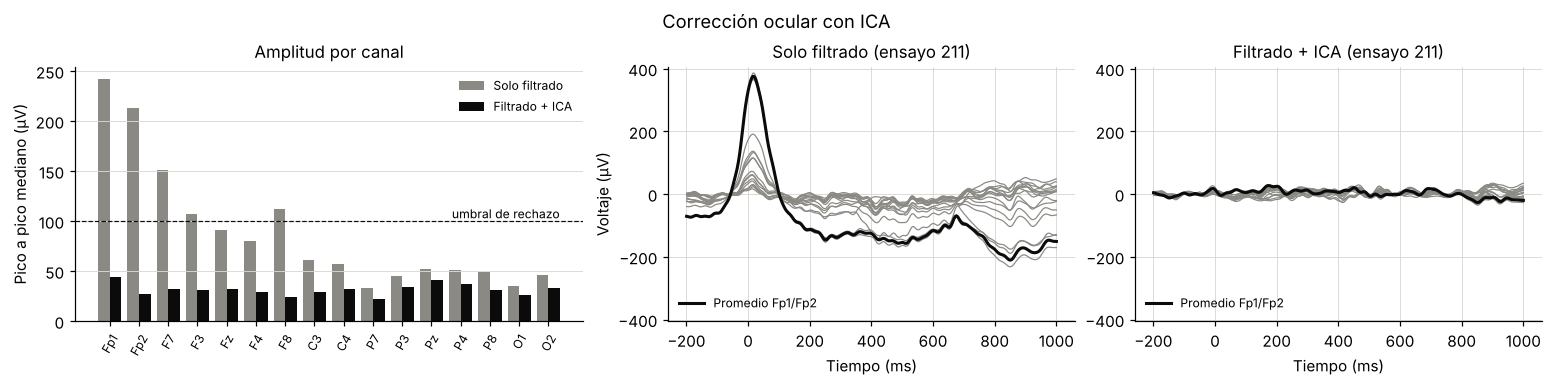

In [12]:
_before = epochs_noica_all.get_data(picks=CH_NAMES) * 1e6
_after = epochs_erp_all.get_data(picks=CH_NAMES) * 1e6
_vp = [CH_NAMES.index(ch) for ch in ICA_VEOG_PROXY]
_worst = int(np.argmax(np.ptp(_before[:, _vp].mean(axis=1), axis=1)))        # ensayo con la mayor deflexión ocular
_t_all = epochs_erp_all.times * 1000
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), gridspec_kw=dict(width_ratios=[1.25, 1, 1]), layout="constrained")
_xpos = np.arange(len(CH_NAMES))
axes[0].bar(_xpos - 0.2, np.median(np.ptp(_before, axis=2), axis=0), width=0.4, color=C_MUTED, label="Solo filtrado")
axes[0].bar(_xpos + 0.2, np.median(np.ptp(_after, axis=2), axis=0), width=0.4, color=C_INK, label="Filtrado + ICA")
axes[0].axhline(REJECT_PTP_UV, color=C_INK, lw=0.8, ls="--")
axes[0].text(len(CH_NAMES) - 0.5, REJECT_PTP_UV, "umbral de rechazo ", ha="right", va="bottom", fontsize=8)
axes[0].set_xticks(_xpos, CH_NAMES, rotation=60, fontsize=8)
axes[0].set(ylabel="Pico a pico mediano (µV)", title="Amplitud por canal")
axes[0].legend(fontsize=8)
axes[0].grid(axis="x", visible=False)
_ylim = 1.05 * np.abs(_before[_worst]).max()
for ax, data, title in ((axes[1], _before, "Solo filtrado"), (axes[2], _after, "Filtrado + ICA")):
    ax.plot(_t_all, data[_worst].T, color=C_MUTED, lw=0.8)
    ax.plot(_t_all, data[_worst, _vp].mean(axis=0), color=C_INK, lw=2, label="Promedio Fp1/Fp2")
    ax.set(title=f"{title} (ensayo {_worst})", xlabel="Tiempo (ms)", ylim=(-_ylim, _ylim))
    ax.legend(loc="lower left", fontsize=8)
axes[1].set_ylabel("Voltaje (µV)")
fig.suptitle(f"Corrección ocular con ICA{DEMO_TAG}")
save_fig(fig, "05_ica_antes_despues")
plt.show()

### 6.5 Movimiento ocular ligado a la tarea
En una tarea con fijación central los parpadeos caen al azar y se promedian. Aquí el participante conduce,
mira el estímulo y baja la mirada al teclado, que estaba abajo y a su derecha, para encontrar la tecla. Los
ojos se mueven entonces de forma *sistemática* después de cada estímulo, y conviene medirlo. La figura promedia, antes del ICA, las dos referencias oculares. Polaridad: como la
córnea es positiva, mirar hacia abajo vuelve negativo el promedio Fp1/Fp2 y mirar a la derecha vuelve
positiva la diferencia F8 − F7.

Si aparece un desplazamiento sistemático, tiene tres consecuencias:
1. **La corrección ocular deja de ser opcional**: sin ella, los "ERP" frontales son el movimiento del ojo.
2. **Las condiciones no quedan igualadas**: si el ojo regresa al responder y la respuesta llega más tarde
   en los ensayos incongruentes, el artefacto se desfasa entre condiciones e imita un efecto de conflicto.
   Por eso la tabla de la sección 9.1 reporta cuánta diferencia ocular se retiró en cada región y ventana.
3. **La corrección tiene un límite**: el ICA separa fuentes que varían de forma independiente, y un
   movimiento ocular que ocurre siempre en el mismo momento del ensayo se traslapa en el tiempo con las ondas
   cerebrales lentas (P3, SP). Parte de una puede quedar asignada a la otra. La sección 9.3 mide ese margen.

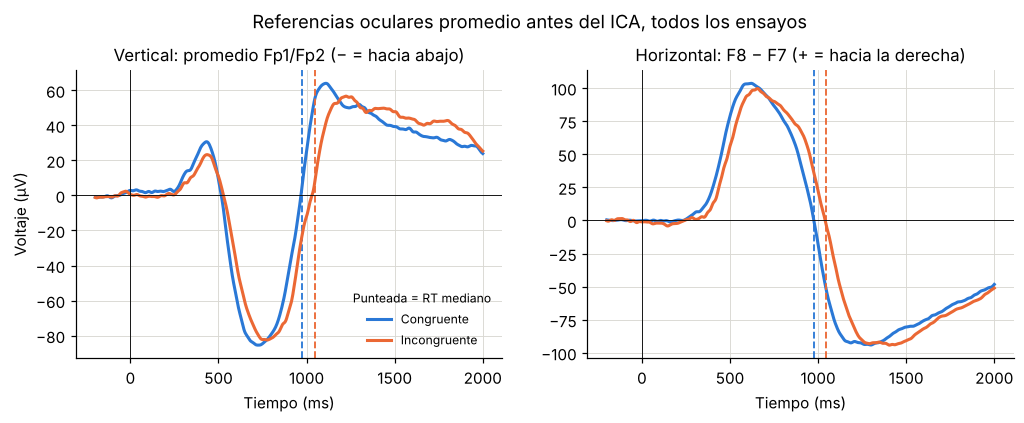

Vertical: desplazamiento sistemático de -84 µV, de ≈ 590 a ≈ 922 ms tras el estímulo (RT mediano: 1004 ms).
Horizontal: desplazamiento sistemático de +101 µV, de ≈ 469 a ≈ 914 ms tras el estímulo (RT mediano: 1004 ms).

Hay un movimiento ocular ligado a la tarea. Interpreta con cautela todo efecto posterior a su inicio y revisa la columna 'ocular retirado' de la sección 9.1.


In [13]:
def half_max_span(wave, times, min_amp_uv=20.0):
    """Inicio y fin (al 50 % del pico) de la deflexión dominante de una onda promedio; None si es menor que min_amp_uv."""
    k = int(np.argmax(np.abs(wave)))
    peak = wave[k]
    if abs(peak) < min_amp_uv:
        return None
    above = wave * np.sign(peak) >= 0.5 * abs(peak)
    start = k - int(np.argmin(above[k::-1])) + 1 if not above[:k + 1].all() else 0
    stop = k + int(np.argmin(above[k:])) - 1 if not above[k:].all() else len(wave) - 1
    return times[start], times[stop], peak


_gaze = epochs_filt.copy().crop(ERP_TMIN, 2.0).apply_baseline(BASELINE)
_gt = _gaze.times
_cond_all = trials["condicion"].to_numpy()
_vertical, _horizontal = eog_proxies(_gaze)
gaze_waves = {"Vertical: promedio Fp1/Fp2 (− = hacia abajo)": _vertical * 1e6,
              "Horizontal: F8 − F7 (+ = hacia la derecha)": _horizontal * 1e6}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
gaze_summary = {}
for ax, (label, waves) in zip(axes, gaze_waves.items()):
    for name in EVENT_ID:
        ax.plot(_gt * 1000, waves[_cond_all == name].mean(axis=0), color=COND_COLORS[name], label=name)
        ax.axvline(behavior[f"RT mediano {name.lower()} (ms)"], color=COND_COLORS[name], ls="--", lw=1.2)
    ax.axhline(0, color=C_INK, lw=0.6)
    ax.axvline(0, color=C_INK, lw=0.6)
    ax.set(title=label, xlabel="Tiempo (ms)")
    gaze_summary[label.split(":")[0]] = half_max_span(waves.mean(axis=0), _gt)
axes[0].set_ylabel("Voltaje (µV)")
axes[0].legend(title="Punteada = RT mediano", fontsize=8, title_fontsize=8)
fig.suptitle(f"Referencias oculares promedio antes del ICA, todos los ensayos{DEMO_TAG}", y=1.04)
save_fig(fig, "06_movimiento_ocular")
plt.show()

GAZE_SHIFT = any(v is not None for v in gaze_summary.values())
for axis_name, span in gaze_summary.items():
    if span is None:
        print(f"{axis_name}: sin desplazamiento sistemático (el promedio no supera 20 µV).")
    else:
        print(f"{axis_name}: desplazamiento sistemático de {span[2]:+.0f} µV, de ≈ {span[0] * 1000:.0f} a ≈ {span[1] * 1000:.0f} ms "
              f"tras el estímulo (RT mediano: {1000 * np.median(np.r_[rt_con, rt_inc]):.0f} ms).")
if GAZE_SHIFT:
    print("\nHay un movimiento ocular ligado a la tarea. Interpreta con cautela todo efecto posterior a su inicio "
          "y revisa la columna 'ocular retirado' de la sección 9.1.")

### 6.6 Dos preguntas, dos filtros
El primer análisis filtró de 4 a 20 Hz a propósito: quería estudiar los ritmos theta, alfa y beta, y dejar
fuera lo más lento (delta, propio del sueño) y lo más rápido, que suele ser ruido. Para estudiar ritmos es una
buena decisión, y este notebook la conserva en la sección 11 (de 4 a 30 Hz, para incluir también la beta alta).

Los potenciales evocados son otra pregunta. Las ondas que deja un estímulo, como la P3 o la N450, son lentas:
suben y bajan a lo largo de medio segundo y casi toda su energía está por debajo de 4 Hz. No son ondas delta
de sueño, pero ocupan las mismas frecuencias, así que un filtro de 4 Hz también se las lleva. Por eso los
potenciales evocados se calculan de 0.1 a 30 Hz. La figura muestra el mismo promedio con cada filtro, sobre
los mismos ensayos y con la misma corrección ocular.

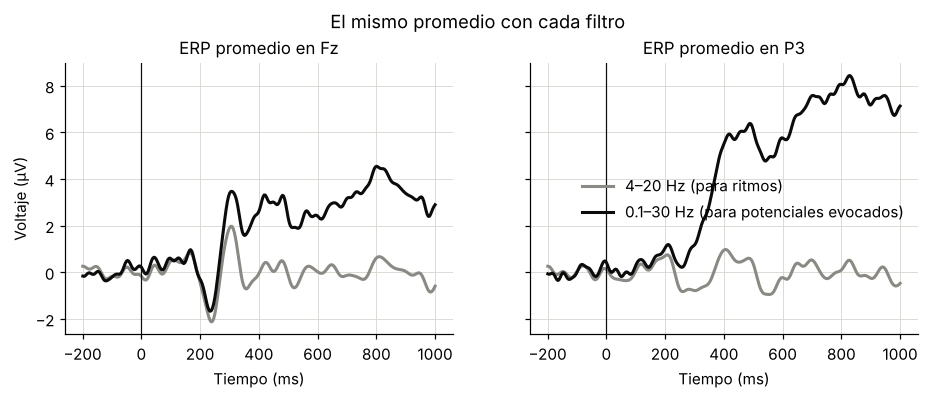

In [14]:
_old = epochs_raw.copy().filter(4.0, 20.0, picks=CH_NAMES)                # filtro original (FIR por defecto de MNE)
if ICA_ENABLED:
    _old = ica.apply(_old)
_old = _old.crop(ERP_TMIN, ERP_TMAX).apply_baseline(BASELINE)[keep].average(picks=CH_NAMES)
_new = epochs.average(picks=CH_NAMES)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, ch in zip(axes, (good("Fz", "F3"), good("Pz", "P3"))):
    ax.plot(times_ms, _old.get_data(picks=ch)[0] * 1e6, color=C_MUTED, label="4–20 Hz (para ritmos)")
    ax.plot(times_ms, _new.get_data(picks=ch)[0] * 1e6, color=C_INK, label="0.1–30 Hz (para potenciales evocados)")
    ax.axvline(0, color=C_INK, lw=0.8)
    ax.set(title=f"ERP promedio en {ch}", xlabel="Tiempo (ms)")
axes[0].set_ylabel("Voltaje (µV)")
axes[1].legend(loc="best")
fig.suptitle(f"El mismo promedio con cada filtro{DEMO_TAG}", y=1.03)
save_fig(fig, "07_filtro_original_vs_actual")
plt.show()

## 7. ERP global
Primero el panorama completo: los 16 canales superpuestos con sus mapas topográficos, por condición,
y la onda de diferencia (Incongruente − Congruente). Con 16 electrodos los mapas son una interpolación
gruesa: sirven para ver si un efecto es frontal o posterior, no para localizarlo. Los canales excluidos
aparecen interpolados a partir de sus vecinos.

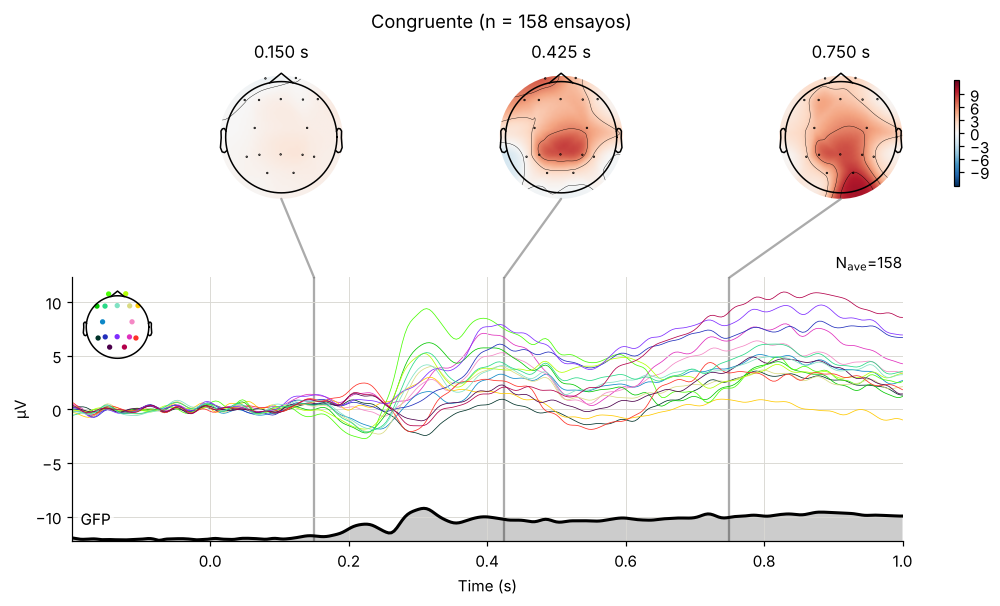

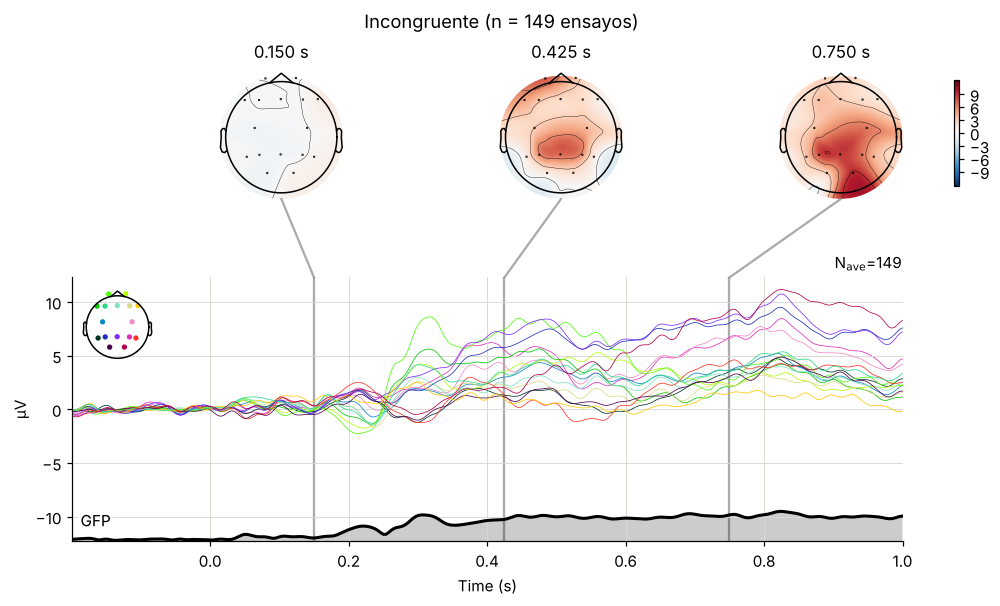

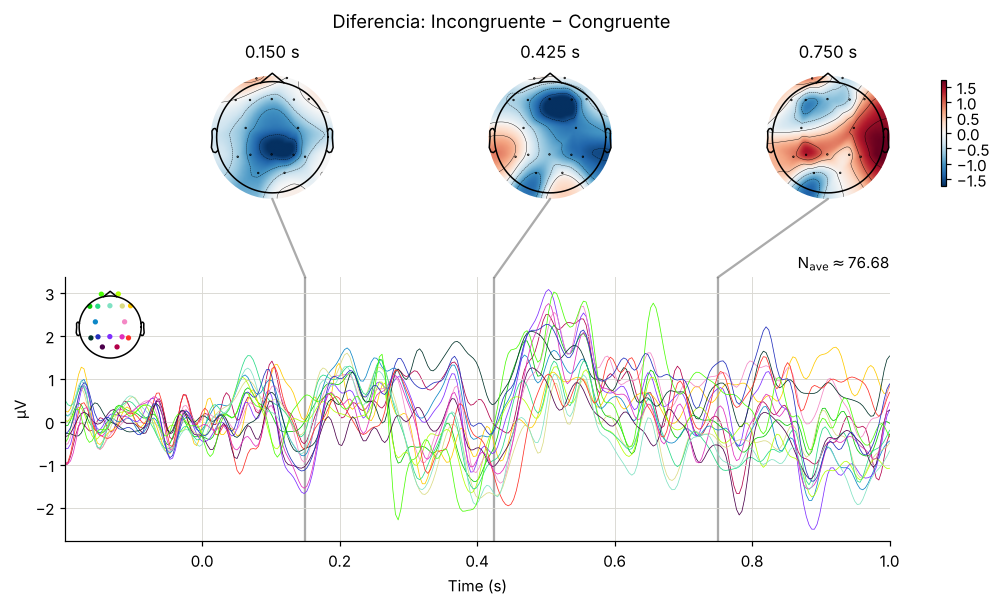

In [15]:
evoked = {name: epochs[name].average() for name in EVENT_ID}
evoked_diff = mne.combine_evoked([evoked["Incongruente"], evoked["Congruente"]], weights=[1, -1])
evoked_diff.comment = "Incongruente − Congruente"
topo_times = [np.mean(w) for w in WINDOWS.values()]

_ylim = 1.1 * max(np.abs(e.data).max() for e in evoked.values()) * 1e6
for name, ev in evoked.items():
    fig = ev.plot_joint(times=topo_times, title=f"{name} (n = {ev.nave} ensayos){DEMO_TAG}", show=False,
                        ts_args=dict(ylim=dict(eeg=[-_ylim, _ylim]), gfp=True),
                        topomap_args=dict(vlim=(-_ylim, _ylim)))
    fig.set_size_inches(9, 5.4)
    save_fig(fig, f"08_erp_global_{name.lower()}")
    plt.show()

fig = evoked_diff.plot_joint(times=topo_times, title=f"Diferencia: Incongruente − Congruente{DEMO_TAG}", show=False)
fig.set_size_inches(9, 5.4)
save_fig(fig, "09_erp_global_diferencia")
plt.show()

## 8. ERP por región de interés
Para cada región se promedian sus electrodos *dentro de cada ensayo* y después se promedian los ensayos.
Así cada ensayo aporta un valor por región, que es lo que permite la estadística de la sección 9.

El análisis original comparaba regiones con el GFP (potencia global de campo). El GFP es siempre positivo:
borra el signo del voltaje, y la N450 es justamente una diferencia de signo. Por eso aquí se usa la media.

### 8.1 Las ocho regiones
Los paneles siguen la disposición de la cabeza vista desde arriba: frente arriba, izquierda a la izquierda.
La banda de color es el intervalo de confianza del 95 % entre ensayos; las franjas grises marcan las
ventanas definidas a priori; la barra negra inferior marca los intervalos con diferencia significativa
entre condiciones según la prueba de permutación por clústeres (sección 9.2).

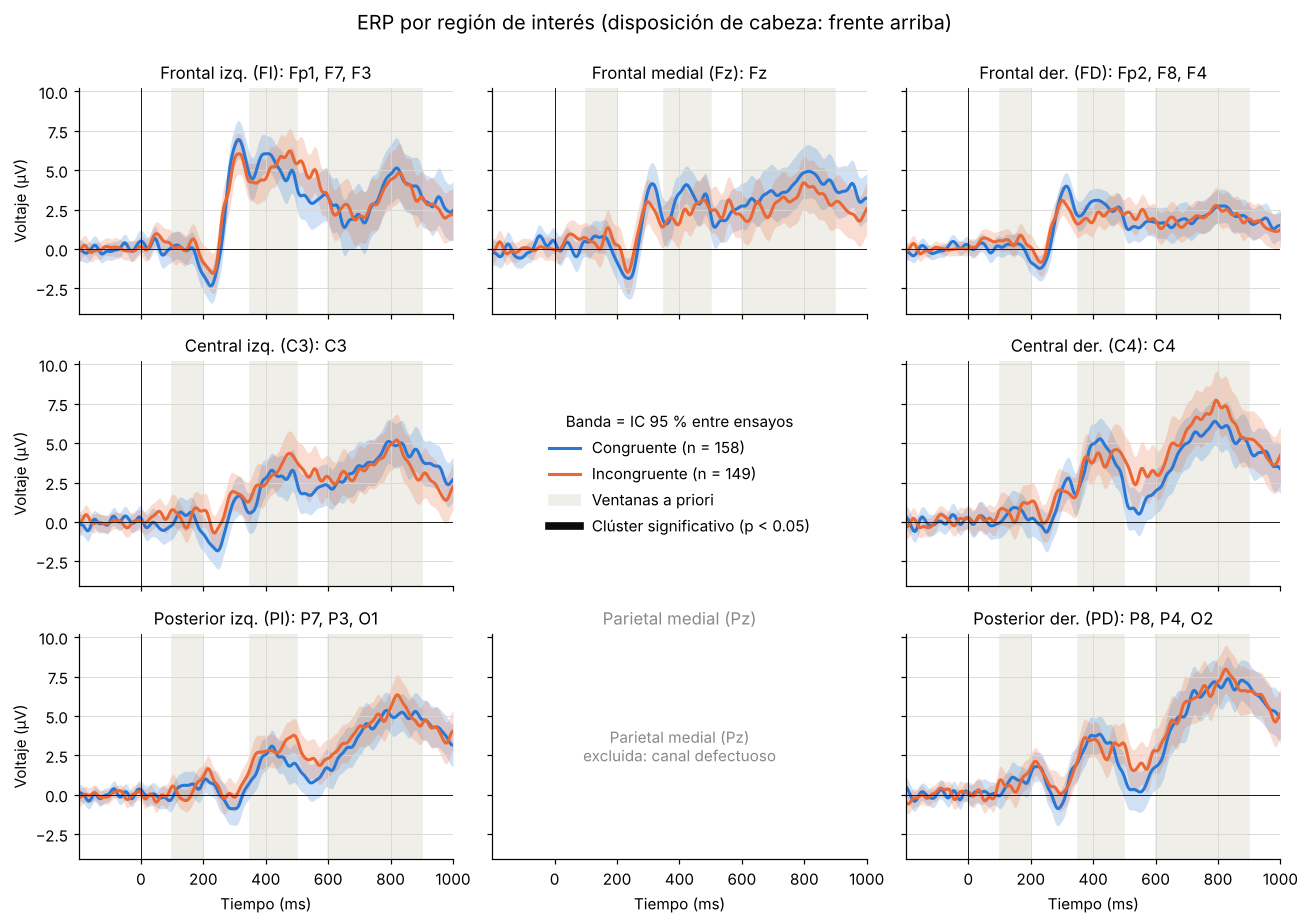

In [16]:
def roi_trials(ep, channels):
    """Señal de una región: promedio de sus canales en cada ensayo. Devuelve ensayos × muestras, en µV."""
    return ep.get_data(picks=channels).mean(axis=1) * 1e6


def mean_ci(x):
    """Media entre ensayos e intervalo de confianza del 95 % (aproximación normal)."""
    m = x.mean(axis=0)
    half = 1.96 * x.std(axis=0, ddof=1) / np.sqrt(x.shape[0])
    return m, m - half, m + half


def cluster_test(a, b):
    """Prueba de permutación por clústeres en el tiempo (Maris y Oostenveld, 2007) para a vs. b.

    Devuelve una lista de (inicio_s, fin_s, p) con los clústeres de p < ALPHA.
    """
    threshold = stats.t.ppf(1 - ALPHA / 2, a.shape[0] + b.shape[0] - 2)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)      # "No clusters found" no es un error
        _, clusters, pvals, _ = mne.stats.permutation_cluster_test(
            [a, b], stat_fun=lambda x, y: stats.ttest_ind(x, y, equal_var=False).statistic,
            threshold=threshold, tail=0, n_permutations=N_PERMUTATIONS, seed=SEED, out_type="mask", verbose=False)
    return sorted((epochs.times[c][0], epochs.times[c][-1], p) for c, p in zip(clusters, pvals) if p < ALPHA)


def plot_roi(ax, data, title, sig=None, show_windows=True):
    """Dibuja Congruente vs. Incongruente con IC 95 % para una región."""
    if show_windows:
        for lo, hi in WINDOWS.values():
            ax.axvspan(lo * 1000, hi * 1000, color="#efeee9", zorder=0)
    for name, mask in (("Congruente", is_con), ("Incongruente", is_inc)):
        m, lo, hi = mean_ci(data[mask])
        ax.fill_between(times_ms, lo, hi, color=COND_COLORS[name], alpha=0.22, lw=0)
        ax.plot(times_ms, m, color=COND_COLORS[name], label=name)
    ax.axhline(0, color=C_INK, lw=0.6)
    ax.axvline(0, color=C_INK, lw=0.6)
    if sig:
        y0 = ax.get_ylim()[0]
        for t0, t1, _ in sig:
            ax.plot([t0 * 1000, t1 * 1000], [y0, y0], color=C_INK, lw=5, solid_capstyle="butt", clip_on=False)
    ax.set_title(title)
    ax.set_xlim(times_ms[0], times_ms[-1])


roi_data = {roi: roi_trials(epochs, chs) for roi, chs in ROIS_ACTIVE.items()}
roi_clusters = {roi: cluster_test(d[is_inc], d[is_con]) for roi, d in roi_data.items()}

HEAD_LAYOUT = {  # (fila, columna) de cada región en una rejilla 3 × 3 con forma de cabeza
    "Frontal izq. (FI)": (0, 0), "Frontal medial (Fz)": (0, 1), "Frontal der. (FD)": (0, 2),
    "Central izq. (C3)": (1, 0), "Central der. (C4)": (1, 2),
    "Posterior izq. (PI)": (2, 0), "Parietal medial (Pz)": (2, 1), "Posterior der. (PD)": (2, 2),
}
fig, axes = plt.subplots(3, 3, figsize=(12, 8.4), sharex=True, sharey=True)
for roi, (r, c) in HEAD_LAYOUT.items():
    if roi in roi_data:
        plot_roi(axes[r, c], roi_data[roi], f"{roi}: {', '.join(ROIS_ACTIVE[roi])}", sig=roi_clusters[roi])
    else:                                                    # región sin canales válidos
        axes[r, c].text(0.5, 0.5, f"{roi}\nexcluida: canal defectuoso", ha="center", va="center",
                        color=C_MUTED, transform=axes[r, c].transAxes)
        axes[r, c].set_title(roi, color=C_MUTED)
        axes[r, c].grid(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Voltaje (µV)")
for ax in axes[2]:
    ax.set_xlabel("Tiempo (ms)")
axes[1, 1].axis("off")
handles = [plt.Line2D([], [], color=COND_COLORS[n], label=f"{n} (n = {m.sum()})") for n, m in (("Congruente", is_con), ("Incongruente", is_inc))]
handles += [plt.Rectangle((0, 0), 1, 1, color="#efeee9", label="Ventanas a priori"),
            plt.Line2D([], [], color=C_INK, lw=5, label=f"Clúster significativo (p < {ALPHA})")]
axes[1, 1].legend(handles=handles, loc="center", fontsize=10, title="Banda = IC 95 % entre ensayos")
fig.suptitle(f"ERP por región de interés (disposición de cabeza: frente arriba){DEMO_TAG}", y=0.995, fontsize=13)
fig.tight_layout()
save_fig(fig, "10_erp_por_roi")
plt.show()

### 8.2 Combinaciones del análisis original
Las mismas doce agrupaciones del notebook original: cada cuadrante solo (columna 1), con su electrodo de
línea media (columna 2) y con su electrodo central (columna 3). Compara cada fila de izquierda a derecha:
si al sumar Fz o Pz el efecto crece, el electrodo medial lo está aportando; si al sumar C3 o C4 se reduce,
la región central tiene la polaridad contraria o no participa. Si un canal está excluido, su combinación
coincide con el cuadrante solo.

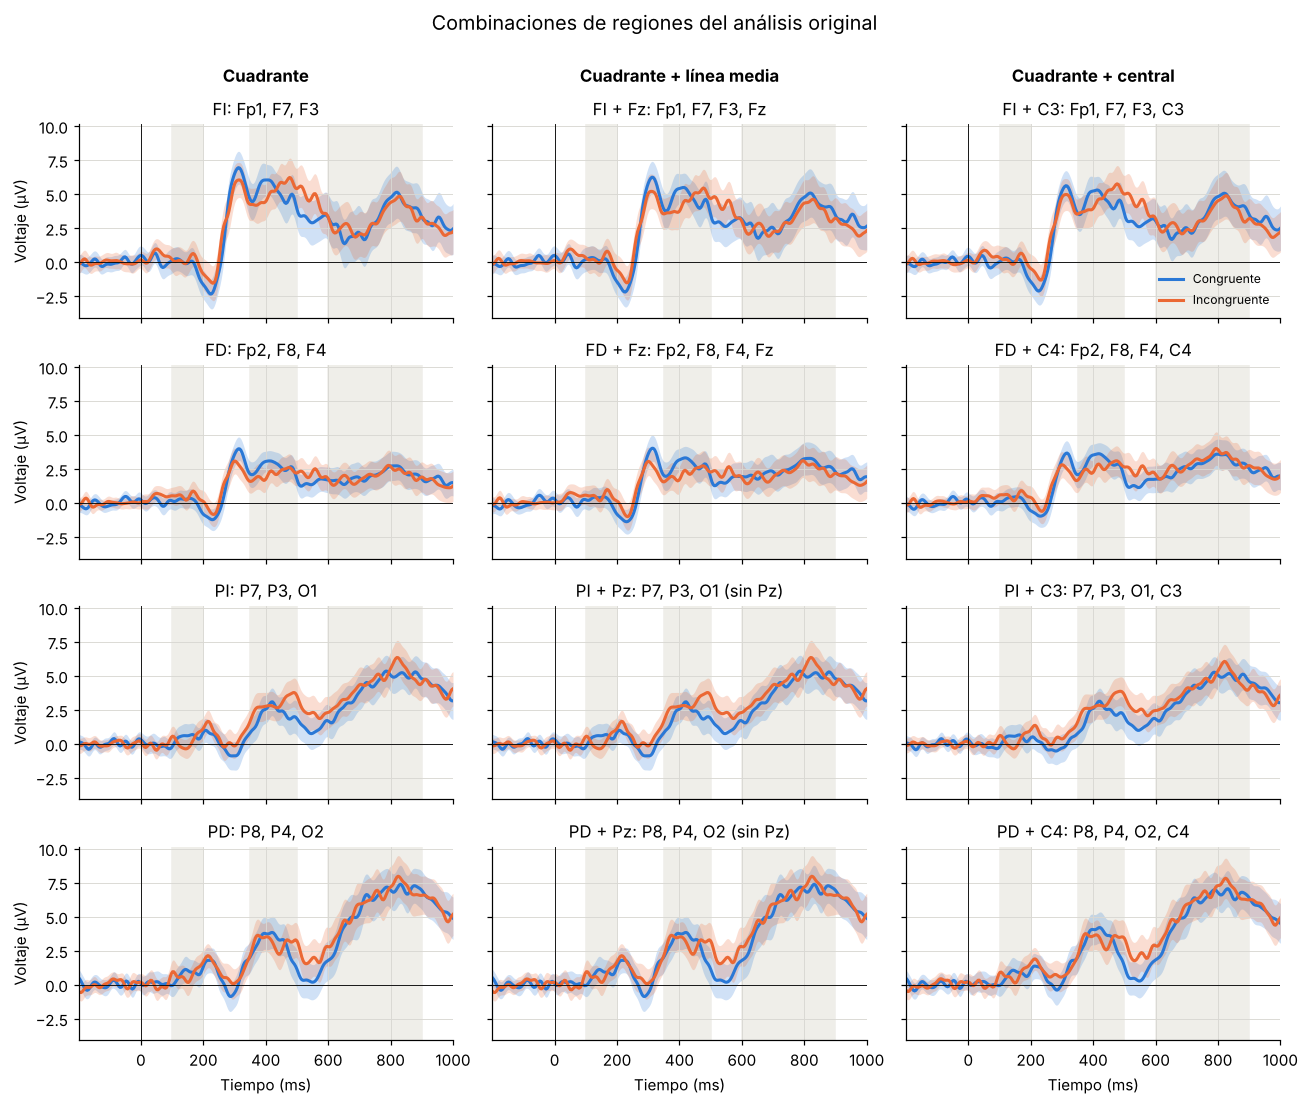

In [17]:
fig, axes = plt.subplots(4, 3, figsize=(12, 10), sharex=True, sharey=True)
for ax, (name, chs) in zip(axes.ravel(), ROIS_COMBINED.items()):
    used = [ch for ch in chs if ch in GOOD_CHANNELS]
    dropped = [ch for ch in chs if ch not in GOOD_CHANNELS]
    plot_roi(ax, roi_trials(epochs, used), f"{name}: {', '.join(used)}" + (f" (sin {', '.join(dropped)})" if dropped else ""))
for ax in axes[:, 0]:
    ax.set_ylabel("Voltaje (µV)")
for ax in axes[-1]:
    ax.set_xlabel("Tiempo (ms)")
axes[0, 2].legend(loc="best", fontsize=8)
for ax, head in zip(axes[0], ("Cuadrante", "Cuadrante + línea media", "Cuadrante + central")):
    ax.annotate(head, xy=(0.5, 1.22), xycoords="axes fraction", ha="center", fontsize=11, fontweight="bold")
fig.suptitle(f"Combinaciones de regiones del análisis original{DEMO_TAG}", y=1.0, fontsize=13)
fig.tight_layout()
save_fig(fig, "11_erp_combinaciones")
plt.show()

## 9. Estadística
Hay un solo participante, así que la unidad de análisis es el **ensayo**: se pregunta si, en esta persona,
los ensayos incongruentes difieren de los congruentes. Las conclusiones valen para este participante;
generalizar a la población requiere repetir el análisis con el resto de la muestra.

### 9.1 Amplitud media por ventana
Para cada región y ventana se promedia el voltaje de cada ensayo y se comparan las condiciones con una
*t* de Welch y una prueba de permutación. Todas las pruebas (regiones × ventanas) se corrigen por
tasa de falsos descubrimientos (FDR de Benjamini-Hochberg). Las ventanas se fijaron antes de ver los
datos, lo que evita elegirlas donde la diferencia "se ve mejor".

La columna **ocular retirado** es la diferencia entre condiciones que tenía, en esa región y ventana, la
actividad que el ICA eliminó. Sirve para juzgar la solidez de cada resultado: si lo retirado es varias
veces mayor que la diferencia que queda, ese resultado depende de que la corrección haya sido casi
perfecta y debe tomarse como frágil.

In [18]:
rows = []
for roi, data in roi_data.items():
    removed = roi_trials(epochs_noica, ROIS_ACTIVE[roi]) - data          # lo que el ICA quitó en esta región
    for win_name, (lo, hi) in WINDOWS.items():
        tmask = (epochs.times >= lo) & (epochs.times <= hi)
        con, inc = data[is_con][:, tmask].mean(axis=1), data[is_inc][:, tmask].mean(axis=1)
        res = stats.ttest_ind(inc, con, equal_var=False)
        ci = res.confidence_interval(0.95)
        rows.append({
            "región": roi, "ventana": win_name,
            "congruente (µV)": con.mean(), "incongruente (µV)": inc.mean(),
            "diferencia (µV)": inc.mean() - con.mean(), "IC95 inf": ci.low, "IC95 sup": ci.high,
            "t": res.statistic, "gl": res.df, "p": res.pvalue,
            "p permutación": permutation_pvalue(inc, con), "d": cohens_d(inc, con),
            "ocular retirado (µV)": removed[is_inc][:, tmask].mean() - removed[is_con][:, tmask].mean(),
        })
stats_table = pd.DataFrame(rows)
stats_table["significativo (FDR)"], stats_table["p FDR"] = mne.stats.fdr_correction(stats_table["p permutación"], alpha=ALPHA)
stats_table.to_csv(os.path.join(OUT_DIR, f"{PARTICIPANT}_estadistica_roi_ventana.csv"), index=False)
stats_table.round({"congruente (µV)": 2, "incongruente (µV)": 2, "diferencia (µV)": 2, "IC95 inf": 2, "IC95 sup": 2,
                   "t": 2, "gl": 0, "p": 4, "p permutación": 4, "p FDR": 4, "d": 2, "ocular retirado (µV)": 2})

,región,ventana,congruente (µV),incongruente (µV),diferencia (µV),IC95 inf,IC95 sup,t,gl,p,p permutación,d,ocular retirado (µV),significativo (FDR),p FDR
0,Frontal izq. (FI),Visual temprano (100–200 ms),-0.24,0.06,0.30,-0.85,1.46,0.52,302.0,0.6051,0.5977,0.06,-1.50,False,0.9894
1,Frontal izq. (FI),Conflicto N450/P3 (350–500 ms),5.15,5.14,-0.01,-1.60,1.58,-0.02,304.0,0.9877,0.9894,-0.00,-1.92,False,0.9894
2,Frontal izq. (FI),SP tardío (600–900 ms),3.20,3.15,-0.05,-2.07,1.98,-0.05,296.0,0.9634,0.9598,-0.01,0.87,False,0.9894
3,Frontal medial (Fz),Visual temprano (100–200 ms),0.42,0.56,0.14,-1.16,1.44,0.21,304.0,0.8312,0.8258,0.02,-1.39,False,0.9894
4,Frontal medial (Fz),Conflicto N450/P3 (350–500 ms),3.06,2.33,-0.73,-2.29,0.82,-0.93,302.0,0.3536,0.3481,-0.11,-3.67,False,0.9894
5,Frontal medial (Fz),SP tardío (600–900 ms),3.87,3.02,-0.85,-2.68,0.98,-0.92,304.0,0.3603,0.3547,-0.10,1.32,False,0.9894
6,Frontal der. (FD),Visual temprano (100–200 ms),0.09,0.48,0.39,-0.45,1.24,0.92,303.0,0.3563,0.3507,0.11,-2.58,False,0.9894
7,Frontal der. (FD),Conflicto N450/P3 (350–500 ms),2.62,2.14,-0.49,-1.53,0.55,-0.92,302.0,0.3574,0.3585,-0.11,-8.97,False,0.9894
8,Frontal der. (FD),SP tardío (600–900 ms),2.02,1.99,-0.04,-1.25,1.17,-0.06,305.0,0.9485,0.9542,-0.01,3.00,False,0.9894
9,Central izq. (C3),Visual temprano (100–200 ms),0.19,0.41,0.22,-0.98,1.41,0.36,305.0,0.7196,0.7265,0.04,-0.74,False,0.9894


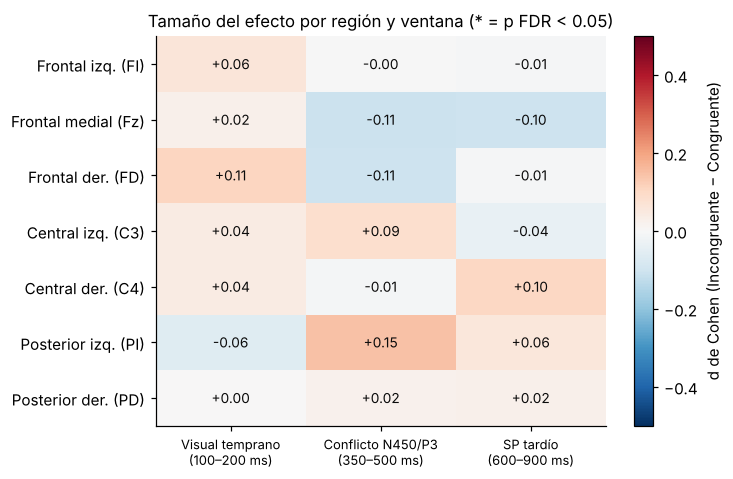

In [19]:
# Mapa de efectos: tamaño de efecto (d) por región y ventana; el asterisco marca lo que sobrevive a FDR.
d_matrix = stats_table.pivot(index="región", columns="ventana", values="d").loc[list(ROIS_ACTIVE), list(WINDOWS)]
sig_matrix = stats_table.pivot(index="región", columns="ventana", values="significativo (FDR)").loc[list(ROIS_ACTIVE), list(WINDOWS)]
vmax = max(0.5, np.abs(d_matrix.to_numpy()).max())
fig, ax = plt.subplots(figsize=(6.6, 4.6))
im = ax.imshow(d_matrix.to_numpy(), cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
for i in range(d_matrix.shape[0]):
    for j in range(d_matrix.shape[1]):
        value = d_matrix.iat[i, j]
        ax.text(j, i, f"{value:+.2f}{' *' if sig_matrix.iat[i, j] else ''}", ha="center", va="center",
                color="white" if abs(value) > 0.6 * vmax else C_INK, fontsize=9)
ax.set_xticks(range(len(WINDOWS)), [w.replace(" (", "\n(") for w in WINDOWS], fontsize=8.5)
ax.set_yticks(range(len(ROIS_ACTIVE)), list(ROIS_ACTIVE))
ax.grid(False)
fig.colorbar(im, ax=ax, label="d de Cohen (Incongruente − Congruente)")
ax.set_title(f"Tamaño del efecto por región y ventana (* = p FDR < {ALPHA}){DEMO_TAG}")
save_fig(fig, "12_mapa_de_efectos")
plt.show()

### 9.2 Prueba de permutación por clústeres
Las ventanas fijas pueden pasar por alto un efecto que cae fuera de ellas. La prueba por clústeres recorre
toda la época sin elegir ventana y controla los falsos positivos sobre el conjunto de muestras.
Indica que las condiciones difieren en algún punto del clúster; sus bordes son aproximados y no deben
leerse como el inicio y el fin exactos del efecto. Cada región se prueba por separado (sin corrección
entre regiones), así que tómalo como complemento de la tabla anterior.

Sin clústeres significativos.


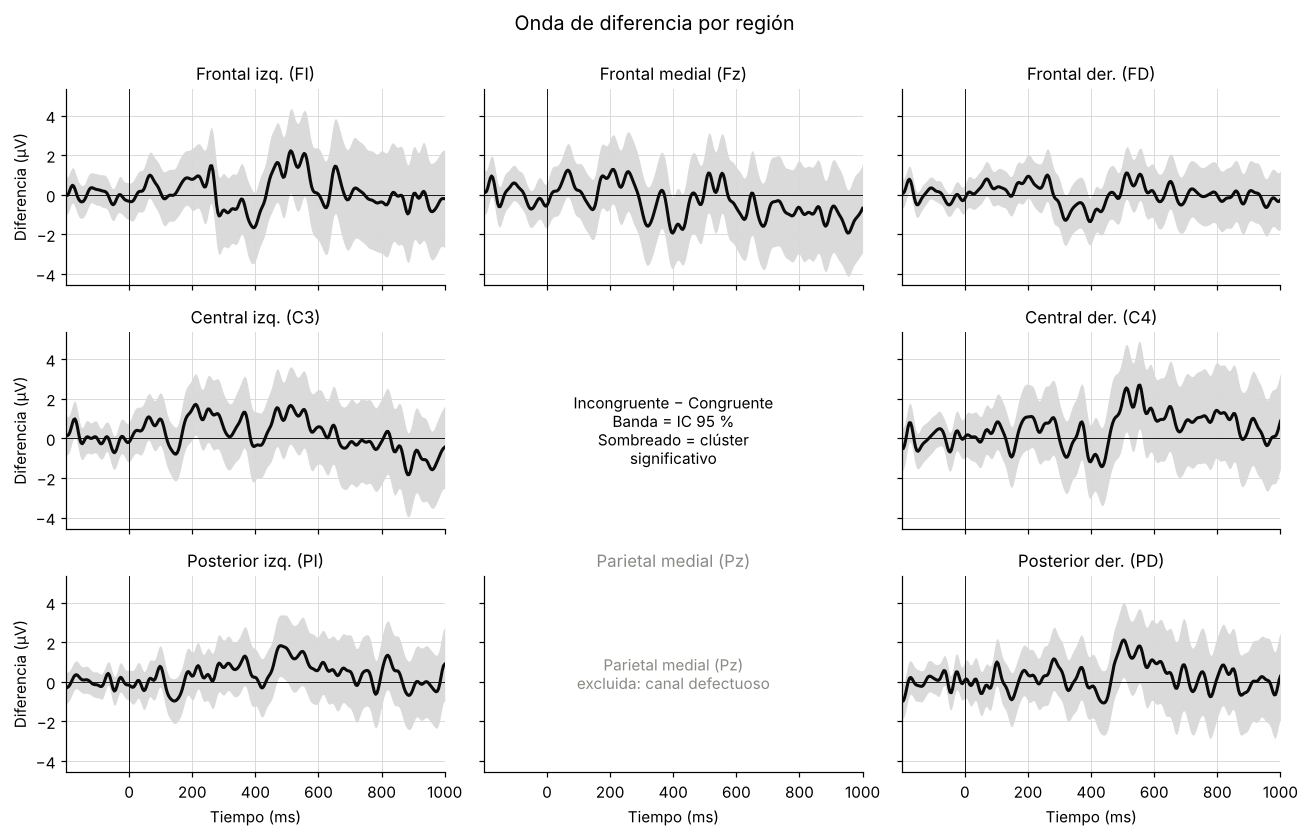

In [20]:
cluster_rows = [{"región": roi, "inicio (ms)": round(t0 * 1000), "fin (ms)": round(t1 * 1000), "p": p}
                for roi, found in roi_clusters.items() for t0, t1, p in found]
cluster_table = pd.DataFrame(cluster_rows, columns=["región", "inicio (ms)", "fin (ms)", "p"])
cluster_table.to_csv(os.path.join(OUT_DIR, f"{PARTICIPANT}_clusters.csv"), index=False)
print("Sin clústeres significativos." if cluster_table.empty else cluster_table.to_string(index=False))

fig, axes = plt.subplots(3, 3, figsize=(12, 7.6), sharex=True, sharey=True)
for roi, (r, c) in HEAD_LAYOUT.items():
    ax = axes[r, c]
    if roi not in roi_data:
        ax.text(0.5, 0.5, f"{roi}\nexcluida: canal defectuoso", ha="center", va="center", color=C_MUTED, transform=ax.transAxes)
        ax.set_title(roi, color=C_MUTED)
        ax.grid(False)
        continue
    diff = roi_data[roi][is_inc].mean(axis=0) - roi_data[roi][is_con].mean(axis=0)
    se = np.sqrt(roi_data[roi][is_inc].var(axis=0, ddof=1) / is_inc.sum() + roi_data[roi][is_con].var(axis=0, ddof=1) / is_con.sum())
    for t0, t1, _ in roi_clusters[roi]:
        ax.axvspan(t0 * 1000, t1 * 1000, color="#d9d8d3", zorder=0)
    ax.fill_between(times_ms, diff - 1.96 * se, diff + 1.96 * se, color=C_INK, alpha=0.15, lw=0)
    ax.plot(times_ms, diff, color=C_INK)
    ax.axhline(0, color=C_INK, lw=0.6)
    ax.axvline(0, color=C_INK, lw=0.6)
    ax.set_title(roi)
    ax.set_xlim(times_ms[0], times_ms[-1])
for ax in axes[:, 0]:
    ax.set_ylabel("Diferencia (µV)")
for ax in axes[2]:
    ax.set_xlabel("Tiempo (ms)")
axes[1, 1].axis("off")
axes[1, 1].text(0.5, 0.5, "Incongruente − Congruente\nBanda = IC 95 %\nSombreado = clúster\nsignificativo",
                ha="center", va="center", fontsize=10, transform=axes[1, 1].transAxes)
fig.suptitle(f"Onda de diferencia por región{DEMO_TAG}", y=0.995, fontsize=13)
fig.tight_layout()
save_fig(fig, "13_onda_de_diferencia")
plt.show()

### 9.3 ¿Cuánto dependen los resultados de la corrección ocular?
El ICA no tiene una solución única: cambia según con qué señal se ajuste. Aquí se repite la corrección
ajustando el ICA con otros dos filtros pasa-altas, igual de defendibles que el principal, y se recalcula
todo sobre los mismos ensayos. Para cada región y ventana se reporta cuánto se mueven el **nivel** del ERP
(promedio de todos los ensayos) y la **diferencia** entre condiciones.

Cómo leerlo: si el nivel cambia varios microvoltios entre variantes, la forma absoluta de la onda en esa
ventana no es interpretable. Si la diferencia apenas cambia, la comparación entre condiciones sí lo es,
porque el residuo ocular afecta a las dos por igual.

In [21]:
def window_summary(ep):
    """Nivel (todos los ensayos) y diferencia Incongruente − Congruente por región y ventana, en µV."""
    out = {}
    for roi, chs in ROIS_ACTIVE.items():
        x = roi_trials(ep, chs)
        for win_name, (lo, hi) in WINDOWS.items():
            tmask = (ep.times >= lo) & (ep.times <= hi)
            out[(roi, win_name)] = (x[:, tmask].mean(), x[is_inc][:, tmask].mean() - x[is_con][:, tmask].mean())
    return out


sensitivity_table, sensitivity_by_window = pd.DataFrame(), pd.DataFrame()
if ICA_ENABLED and ICA_SENSITIVITY_HP:
    variants = {f"principal ({ICA_HP_FREQ:g} Hz)": window_summary(epochs)}
    # Con épocas ya cortadas (.mat) un pasa-altas menor que 1 Hz no cabe en 6 s: esas variantes se omiten.
    for hp in [hp for hp in ICA_SENSITIVITY_HP if INPUT_KIND == "dat" or hp >= 1.0]:
        ica_alt, _ = fit_ocular_ica(filtered_epochs(hp))
        ep_alt = ica_alt.apply(epochs_filt.copy()).crop(ERP_TMIN, ERP_TMAX).apply_baseline(BASELINE)[keep]
        variants[f"ajuste a {hp:g} Hz"] = window_summary(ep_alt)
        print(f"ICA ajustado a {hp:g} Hz: componentes retirados {ica_alt.exclude}")
    levels = pd.DataFrame({name: {k: v[0] for k, v in res.items()} for name, res in variants.items()})
    diffs = pd.DataFrame({name: {k: v[1] for k, v in res.items()} for name, res in variants.items()})
    sensitivity_table = pd.DataFrame({
        "diferencia principal (µV)": diffs.iloc[:, 0], "diferencia mín (µV)": diffs.min(axis=1),
        "diferencia máx (µV)": diffs.max(axis=1), "cambio de la diferencia (µV)": diffs.max(axis=1) - diffs.min(axis=1),
        "cambio del nivel (µV)": levels.max(axis=1) - levels.min(axis=1),
    })
    sensitivity_table.index.names = ["región", "ventana"]
    sensitivity_table = sensitivity_table.reset_index()
    sensitivity_table.to_csv(os.path.join(OUT_DIR, f"{PARTICIPANT}_sensibilidad_ica.csv"), index=False)
    sensitivity_by_window = (sensitivity_table.groupby("ventana", sort=False)[["cambio del nivel (µV)", "cambio de la diferencia (µV)"]]
                             .max().rename(columns=lambda c: "máximo " + c))
    print("\nMayor cambio entre variantes, por ventana:")
    print(sensitivity_by_window.round(2).to_string())
sensitivity_table.round(2)

ICA ajustado a 0.5 Hz: componentes retirados [0, 1, 2]


ICA ajustado a 2 Hz: componentes retirados [0, 1, 2]

Mayor cambio entre variantes, por ventana:
                                máximo cambio del nivel (µV)  máximo cambio de la diferencia (µV)
ventana                                                                                          
Visual temprano (100–200 ms)                            0.63                                 0.35
Conflicto N450/P3 (350–500 ms)                          2.81                                 0.72
SP tardío (600–900 ms)                                  6.57                                 0.59


,región,ventana,diferencia principal (µV),diferencia mín (µV),diferencia máx (µV),cambio de la diferencia (µV),cambio del nivel (µV)
0,Frontal izq. (FI),Visual temprano (100–200 ms),0.30,0.30,0.65,0.35,0.63
1,Frontal izq. (FI),Conflicto N450/P3 (350–500 ms),-0.01,-0.43,0.29,0.72,2.81
2,Frontal izq. (FI),SP tardío (600–900 ms),-0.05,-0.23,0.36,0.59,6.57
3,Frontal medial (Fz),Visual temprano (100–200 ms),0.14,0.12,0.25,0.14,0.33
4,Frontal medial (Fz),Conflicto N450/P3 (350–500 ms),-0.73,-1.02,-0.61,0.40,1.10
5,Frontal medial (Fz),SP tardío (600–900 ms),-0.85,-0.97,-0.74,0.23,5.11
6,Frontal der. (FD),Visual temprano (100–200 ms),0.39,0.39,0.49,0.10,0.23
7,Frontal der. (FD),Conflicto N450/P3 (350–500 ms),-0.49,-0.77,-0.32,0.45,0.72
8,Frontal der. (FD),SP tardío (600–900 ms),-0.04,-0.13,0.10,0.23,2.24
9,Central izq. (C3),Visual temprano (100–200 ms),0.22,0.17,0.31,0.15,0.27


## 10. Lateralización
¿El efecto de conflicto es mayor en un hemisferio? Para cada ensayo se calcula la diferencia
izquierda − derecha entre regiones homólogas y se compara entre condiciones. Un resultado significativo
equivale a una interacción condición × hemisferio.

In [22]:
PAIRS = {"Frontal (FI − FD)": ("Frontal izq. (FI)", "Frontal der. (FD)"),
         "Central (C3 − C4)": ("Central izq. (C3)", "Central der. (C4)"),
         "Posterior (PI − PD)": ("Posterior izq. (PI)", "Posterior der. (PD)")}
rows = []
for pair, (left, right) in PAIRS.items():
    if left not in roi_data or right not in roi_data:
        continue
    asym = roi_data[left] - roi_data[right]                 # ensayos × muestras
    for win_name, (lo, hi) in WINDOWS.items():
        tmask = (epochs.times >= lo) & (epochs.times <= hi)
        con, inc = asym[is_con][:, tmask].mean(axis=1), asym[is_inc][:, tmask].mean(axis=1)
        rows.append({"par": pair, "ventana": win_name,
                     "asimetría congruente (µV)": con.mean(), "asimetría incongruente (µV)": inc.mean(),
                     "interacción (µV)": inc.mean() - con.mean(),
                     "p permutación": permutation_pvalue(inc, con), "d": cohens_d(inc, con)})
lateral_table = pd.DataFrame(rows)
lateral_table["significativo (FDR)"], lateral_table["p FDR"] = mne.stats.fdr_correction(lateral_table["p permutación"], alpha=ALPHA)
lateral_table.to_csv(os.path.join(OUT_DIR, f"{PARTICIPANT}_lateralizacion.csv"), index=False)
lateral_table.round(3)

,par,ventana,asimetría congruente (µV),asimetría incongruente (µV),interacción (µV),p permutación,d,significativo (FDR),p FDR
0,Frontal (FI − FD),Visual temprano (100–200 ms),-0.332,-0.424,-0.092,0.756,-0.035,False,0.980
1,Frontal (FI − FD),Conflicto N450/P3 (350–500 ms),2.526,3.001,0.474,0.313,0.116,False,0.705
2,Frontal (FI − FD),SP tardío (600–900 ms),1.175,1.167,-0.008,0.991,-0.001,False,0.991
3,Central (C3 − C4),Visual temprano (100–200 ms),-0.321,-0.333,-0.013,0.968,-0.005,False,0.991
4,Central (C3 − C4),Conflicto N450/P3 (350–500 ms),-1.492,-0.861,0.631,0.154,0.163,False,0.461
5,Central (C3 − C4),SP tardío (600–900 ms),-1.079,-2.270,-1.191,0.037,-0.236,False,0.333
6,Posterior (PI − PD),Visual temprano (100–200 ms),-0.279,-0.548,-0.269,0.434,-0.090,False,0.781
7,Posterior (PI − PD),Conflicto N450/P3 (350–500 ms),-0.816,-0.161,0.655,0.121,0.175,False,0.461
8,Posterior (PI − PD),SP tardío (600–900 ms),-1.697,-1.526,0.171,0.762,0.033,False,0.980


## 11. Tiempo-frecuencia: theta frontal y ritmos motores
El ERP solo conserva la actividad que ocurre con la misma fase en todos los ensayos. Las oscilaciones
inducidas por el conflicto varían de fase entre ensayos y se pierden al promediar, pero aparecen al medir
la **potencia**. El marcador más robusto del control cognitivo es el aumento de **theta (4–8 Hz) frontal
medial** (Cavanagh y Frank, 2014). En C3/C4 se espera además una caída de potencia mu/beta (8–30 Hz)
alrededor de la respuesta: la huella de la preparación motora.

La potencia se calcula con ondículas de Morlet sobre la época larga y se expresa en decibeles respecto a
la línea base (−500 a −200 ms), común a las dos condiciones para que la comparación sea justa.
Los movimientos oculares también generan potencia en frecuencias bajas: el resultado de theta se apoya
en la misma corrección por ICA que los ERP.

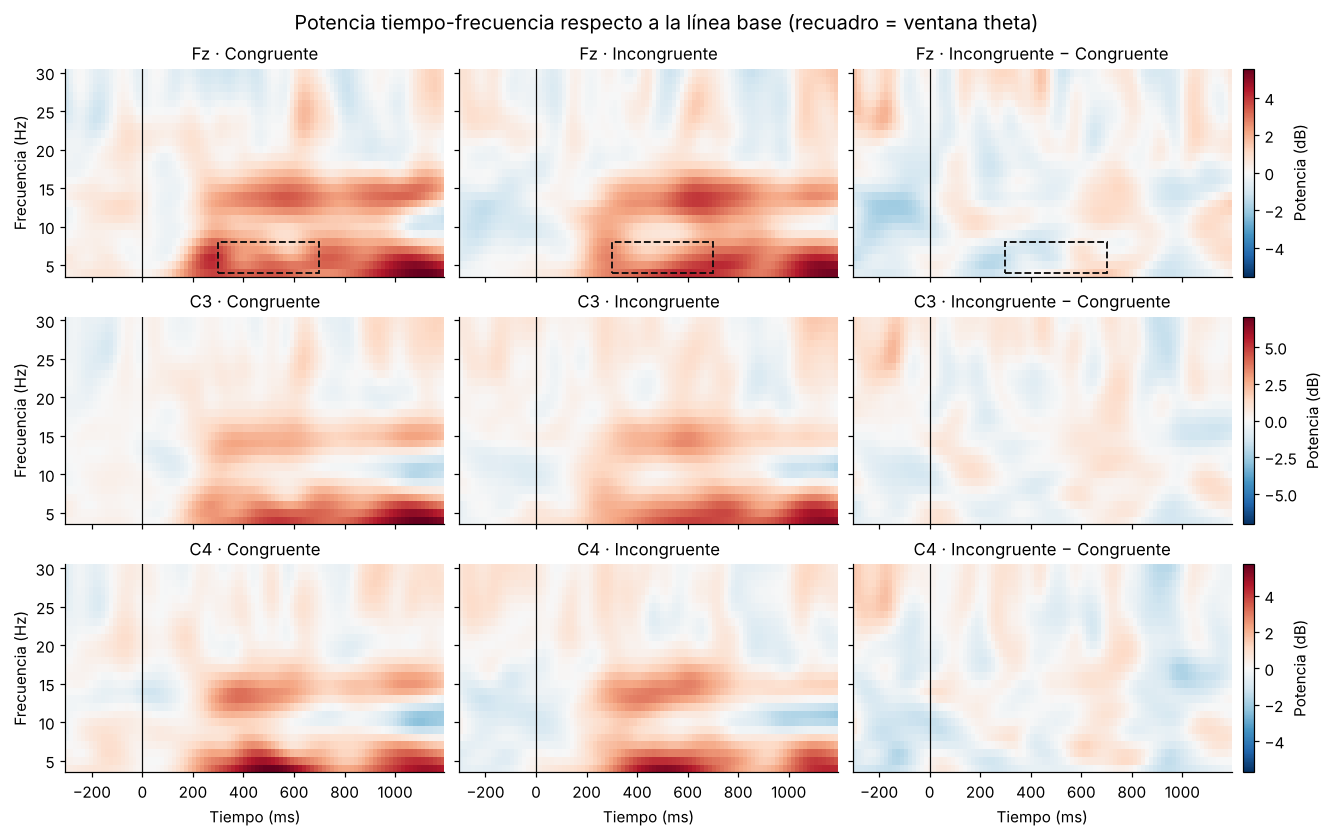

In [23]:
tfr_freqs = np.arange(TFR_FMIN, TFR_FMAX + 1, 1.0)
tfr_cycles = np.clip(tfr_freqs / 2.0, 3.0, 7.0)             # más ciclos a frecuencias altas
tfr = epochs_long.copy().crop(-1.0, 2.5).compute_tfr(
    "morlet", freqs=tfr_freqs, n_cycles=tfr_cycles, decim=4, average=False, return_itc=False)
power = tfr.data                                            # ensayos × canales × frecuencias × tiempos
tfr_times = tfr.times
_bmask = (tfr_times >= TFR_BASELINE[0]) & (tfr_times <= TFR_BASELINE[1])
baseline_power = power[..., _bmask].mean(axis=(0, 3))       # canales × frecuencias, común a ambas condiciones
power_db = {name: 10 * np.log10(power[mask].mean(axis=0) / baseline_power[..., None])
            for name, mask in (("Congruente", is_con), ("Incongruente", is_inc))}
power_db_diff = power_db["Incongruente"] - power_db["Congruente"]

_show = (tfr_times >= -0.3) & (tfr_times <= 1.2)
tfr_channels = [ch for ch in TFR_CHANNELS if ch in GOOD_CHANNELS]
fig, axes = plt.subplots(len(tfr_channels), 3, figsize=(12, 2.5 * len(tfr_channels)), sharex=True, sharey=True,
                         layout="constrained")
for r, ch in enumerate(tfr_channels):
    ci = CH_NAMES.index(ch)
    v = np.abs(np.stack([power_db["Congruente"][ci], power_db["Incongruente"][ci]])[..., _show]).max()
    for c, (label, img) in enumerate((("Congruente", power_db["Congruente"][ci]),
                                      ("Incongruente", power_db["Incongruente"][ci]),
                                      ("Incongruente − Congruente", power_db_diff[ci]))):
        ax = axes[r, c]
        mesh = ax.pcolormesh(tfr_times[_show] * 1000, tfr_freqs, img[:, _show], cmap="RdBu_r", vmin=-v, vmax=v, shading="auto")
        ax.axvline(0, color=C_INK, lw=0.8)
        ax.grid(False)
        ax.set_title(f"{ch} · {label}")
        if ch == "Fz":                                       # recuadro de la ventana theta analizada
            ax.add_patch(plt.Rectangle((THETA_WINDOW[0] * 1000, THETA_BAND[0]), 1000 * (THETA_WINDOW[1] - THETA_WINDOW[0]),
                                       THETA_BAND[1] - THETA_BAND[0], fill=False, ec=C_INK, lw=1.2, ls="--"))
    fig.colorbar(mesh, ax=axes[r, :], label="Potencia (dB)", pad=0.01)
    axes[r, 0].set_ylabel("Frecuencia (Hz)")
for ax in axes[-1]:
    ax.set_xlabel("Tiempo (ms)")
fig.suptitle(f"Potencia tiempo-frecuencia respecto a la línea base (recuadro = ventana theta){DEMO_TAG}", fontsize=13)
save_fig(fig, "14_tiempo_frecuencia")
plt.show()

theta Fz congruente (dB)             2.09
theta Fz incongruente (dB)           1.78
diferencia (dB)                     -0.31
t de Welch                          -1.04
p (Welch)                             0.3
p (permutación)                     0.299
d de Cohen                          -0.12


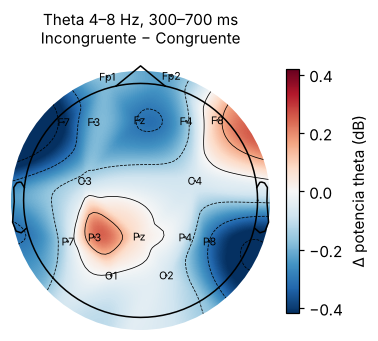

In [24]:
# Theta frontal ensayo por ensayo: ¿es mayor en incongruente?
_fmask = (tfr_freqs >= THETA_BAND[0]) & (tfr_freqs <= THETA_BAND[1])
_tmask = (tfr_times >= THETA_WINDOW[0]) & (tfr_times <= THETA_WINDOW[1])
theta_db = 10 * np.log10((power[:, :, _fmask][..., _tmask] / baseline_power[None, :, _fmask, None]).mean(axis=(2, 3)))  # ensayos × canales
_fz = CH_NAMES.index("Fz")
theta_res = stats.ttest_ind(theta_db[is_inc, _fz], theta_db[is_con, _fz], equal_var=False)
theta_stats = {
    "theta Fz congruente (dB)": theta_db[is_con, _fz].mean(),
    "theta Fz incongruente (dB)": theta_db[is_inc, _fz].mean(),
    "diferencia (dB)": theta_db[is_inc, _fz].mean() - theta_db[is_con, _fz].mean(),
    "t de Welch": theta_res.statistic, "p (Welch)": theta_res.pvalue,
    "p (permutación)": permutation_pvalue(theta_db[is_inc, _fz], theta_db[is_con, _fz]),
    "d de Cohen": cohens_d(theta_db[is_inc, _fz], theta_db[is_con, _fz]),
}
for k, v in theta_stats.items():
    print(f"{k:<30s} {v:>10.3g}" if k.startswith("p ") else f"{k:<30s} {v:>10.2f}")

theta_diff_topo = theta_db[is_inc].mean(axis=0) - theta_db[is_con].mean(axis=0)
fig, ax = plt.subplots(figsize=(3.8, 3.6))
v = np.abs(theta_diff_topo).max()
im, _ = mne.viz.plot_topomap(theta_diff_topo, epochs.info, axes=ax, cmap="RdBu_r", vlim=(-v, v), show=False, names=CH_NAMES)
fig.colorbar(im, ax=ax, label="Δ potencia theta (dB)", shrink=0.8)
ax.set_title(f"Theta {THETA_BAND[0]:.0f}–{THETA_BAND[1]:.0f} Hz, {THETA_WINDOW[0] * 1000:.0f}–{THETA_WINDOW[1] * 1000:.0f} ms\n"
             f"Incongruente − Congruente{DEMO_TAG}", fontsize=10)
save_fig(fig, "15_theta_topografia")
plt.show()

## 12. ERP ensayo por ensayo
Cada fila de la imagen es un ensayo, ordenados del más rápido al más lento; la línea negra marca el momento
de la respuesta. La actividad ligada al **estímulo** forma bandas verticales (misma latencia en todos los
ensayos); la ligada a la **respuesta** sigue la curva del RT. Es la forma más directa de ver qué parte
del ERP es percepción y qué parte es decisión o movimiento.

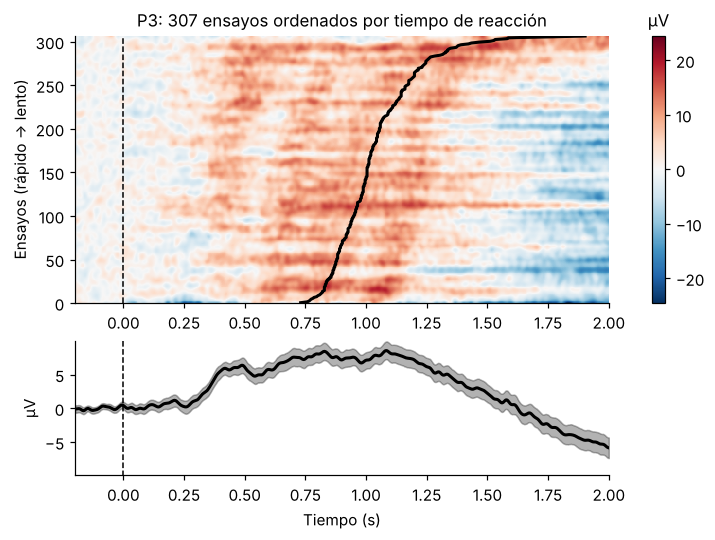

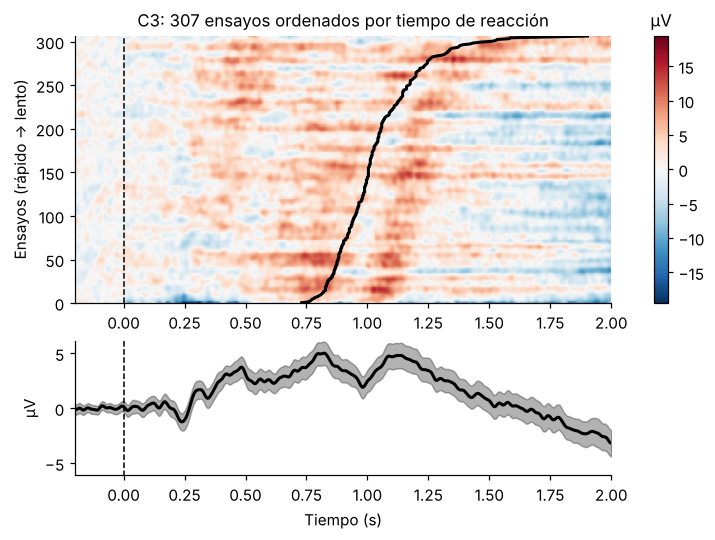

In [25]:
_img_tmax = min(2.0, EPOCH_TMAX)                            # ventana más larga para que quepan casi todos los RT
_rt = md["rt"].to_numpy()
_in_window = md["rt_valido"].to_numpy() & (_rt < _img_tmax)
if _in_window.sum() >= 20:
    _ep = epochs_long[_in_window].copy().crop(ERP_TMIN, _img_tmax).apply_baseline(BASELINE)
    _order = np.argsort(_rt[_in_window])
    for ch in (good("Pz", "P3"), "C3"):
        with plt.rc_context({"axes.grid": False}):
            figs = _ep.plot_image(picks=[ch], order=_order, overlay_times=_rt[_in_window], sigma=3.0, show=False,
                                  title=f"{ch}: {int(_in_window.sum())} ensayos ordenados por tiempo de reacción{DEMO_TAG}",
                                  ts_args=dict(show_sensors=False), evoked=True, colorbar=True)
        figs[0].axes[0].set_ylabel("Ensayos (rápido → lento)")
        figs[0].axes[1].set_xlabel("Tiempo (s)")
        save_fig(figs[0], f"16_erp_por_ensayo_{ch}")
        plt.show()
else:
    print("No hay suficientes ensayos con RT válido dentro de la ventana para esta figura.")

## 13. Fatiga (exploratorio)
El experimento estaba pensado para cansar al participante con la conducción y ver cómo cambiaban sus
respuestas. Con estos datos hay tres formas de buscar ese cansancio:

1. **En la conducta**, bloque a bloque: si hay fatiga, las respuestas se vuelven más lentas o menos exactas.
2. **En la respuesta del cerebro a cada estímulo**: la positividad parietal (350–600 ms) suele encogerse
   cuando baja la atención. Se mide en P3 y P4, los vecinos sanos de Pz.
3. **En los ritmos y los parpadeos**: la fatiga suele aumentar theta y alfa. Se comparan las dos líneas base
   (antes y después de la tarea) y se sigue la evolución minuto a minuto durante la tarea.

Todo en esta sección es descriptivo: es un solo participante, no sabemos qué hacía en las líneas base, y los
segmentos de un mismo registro no son independientes, así que los valores p solo orientan.

### 13.1 Durante la tarea: conducta y respuesta parietal por bloque

        RT congruente (ms)  RT incongruente (ms)  efecto Stroop (ms)  exactitud (%)  respuesta parietal (µV)  ± EEM
bloque                                                                                                             
1                    951.2                1123.0               171.9           97.5                      2.9    0.8
2                    984.4                1056.6                72.3           97.5                      5.5    0.8
3                    959.0                1011.7                52.7          100.0                      4.3    0.8
4                    984.4                1015.6                31.2           97.5                      6.2    0.7

Tendencia del RT, congruente: ρ = -0.06, p = 0.487; -0.7 ms por minuto (IC 95 %: -3.0 a +1.4)
Tendencia del RT, incongruente: ρ = -0.21, p = 0.007; -3.5 ms por minuto (IC 95 %: -6.2 a -1.1)
Tendencia de la respuesta parietal: ρ = +0.12, p = 0.043


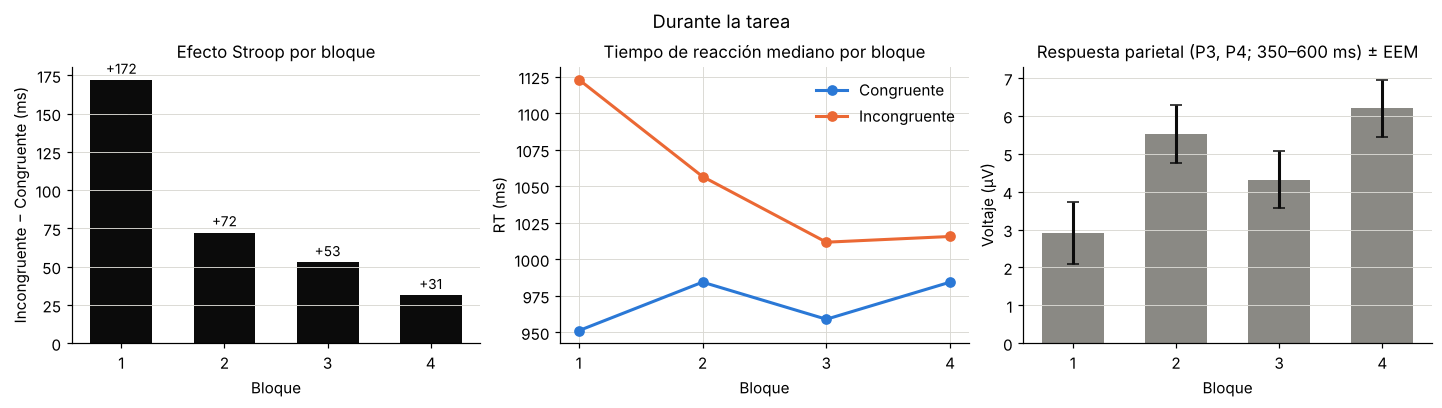

In [26]:
_ok = trials[trials["analizable"]]
rows = []
for b, g in trials.groupby("bloque"):
    g_ok = g[g["analizable"]]
    rt_c = g_ok.loc[g_ok["condicion"] == "Congruente", "rt"].median()
    rt_i = g_ok.loc[g_ok["condicion"] == "Incongruente", "rt"].median()
    rows.append({"bloque": b, "RT congruente (ms)": 1000 * rt_c, "RT incongruente (ms)": 1000 * rt_i,
                 "efecto Stroop (ms)": 1000 * (rt_i - rt_c),
                 "exactitud (%)": 100 * g["correcta"].mean() if HAS_ACCURACY else np.nan})
fatigue_blocks = pd.DataFrame(rows).set_index("bloque")

# Tendencia ensayo a ensayo del RT, por condición
rt_trend = {}
for name in EVENT_ID:
    g = _ok[_ok["condicion"] == name]
    r = stats.spearmanr(g["ensayo"], g["rt"])
    rt_trend[name] = {"rho": r.statistic, "p": r.pvalue}
    if g["minuto"].notna().all():
        sl = stats.theilslopes(1000 * g["rt"], g["minuto"])
        rt_trend[name].update(pendiente=sl.slope, ic=(sl.low_slope, sl.high_slope))

# Respuesta parietal por bloque (datos limpios, ensayos conservados)
_att_chs = [c for c in ATTENTION_CHANNELS if c in GOOD_CHANNELS]
_tmask = (epochs.times >= ATTENTION_WINDOW[0]) & (epochs.times <= ATTENTION_WINDOW[1])
attention = epochs.get_data(picks=_att_chs)[:, :, _tmask].mean(axis=(1, 2)) * 1e6
att_blocks = pd.DataFrame({"bloque": md["bloque"], "amp": attention}).groupby("bloque")["amp"].agg(["mean", "sem", "size"])
att_trend = stats.spearmanr(md["ensayo"], attention)
fatigue_blocks["respuesta parietal (µV)"] = att_blocks["mean"]
fatigue_blocks["± EEM"] = att_blocks["sem"]
fatigue_blocks.to_csv(os.path.join(OUT_DIR, f"{PARTICIPANT}_fatiga_por_bloque.csv"))
print(fatigue_blocks.round(1).to_string())
print()
for name, tr_ in rt_trend.items():
    extra = f"; {tr_['pendiente']:+.1f} ms por minuto (IC 95 %: {tr_['ic'][0]:+.1f} a {tr_['ic'][1]:+.1f})" if "pendiente" in tr_ else ""
    print(f"Tendencia del RT, {name.lower()}: ρ = {tr_['rho']:+.2f}, p = {tr_['p']:.3f}{extra}")
print(f"Tendencia de la respuesta parietal: ρ = {att_trend.statistic:+.2f}, p = {att_trend.pvalue:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout="constrained")
_b = fatigue_blocks.index.to_numpy()
bars = axes[0].bar(_b, fatigue_blocks["efecto Stroop (ms)"], color=C_INK, width=0.6)
axes[0].bar_label(bars, fmt="%+.0f", padding=2, fontsize=9)
axes[0].axhline(0, color=C_INK, lw=0.6)
axes[0].set(title="Efecto Stroop por bloque", xlabel="Bloque", ylabel="Incongruente − Congruente (ms)", xticks=_b)
axes[0].grid(axis="x", visible=False)
for name, col in (("Congruente", "RT congruente (ms)"), ("Incongruente", "RT incongruente (ms)")):
    axes[1].plot(_b, fatigue_blocks[col], "o-", color=COND_COLORS[name], label=name)
axes[1].set(title="Tiempo de reacción mediano por bloque", xlabel="Bloque", ylabel="RT (ms)", xticks=_b)
axes[1].legend()
axes[2].bar(_b, att_blocks["mean"], yerr=att_blocks["sem"], color=C_MUTED, width=0.6, capsize=4, ecolor=C_INK)
axes[2].set(title=f"Respuesta parietal ({', '.join(_att_chs)}; {ATTENTION_WINDOW[0] * 1000:.0f}–{ATTENTION_WINDOW[1] * 1000:.0f} ms) ± EEM",
            xlabel="Bloque", ylabel="Voltaje (µV)", xticks=_b)
axes[2].grid(axis="x", visible=False)
fig.suptitle(f"Durante la tarea{DEMO_TAG}")
save_fig(fig, "17_fatiga_por_bloque")
plt.show()

### 13.2 Ritmos y parpadeos: minuto a minuto, y antes contra después
La señal continua se filtra de 1 a 40 Hz, se le aplica la misma corrección ocular y se corta en segmentos de
4 s; los segmentos con más de 100 µV pico a pico se descartan y se toma la mediana del espectro. Los
parpadeos se cuentan como picos del promedio Fp1/Fp2 por encima de 80 µV.

Parpadeos por minuto en cada bloque: [23.6, 23.8, 21.6, 20.2]
Tendencia por minuto, parpadeos: ρ = -0.46, p = 0.006
Tendencia por minuto, alfa posterior: ρ = -0.09, p = 0.623
Tendencia por minuto, theta frontal: ρ = +0.07, p = 0.683


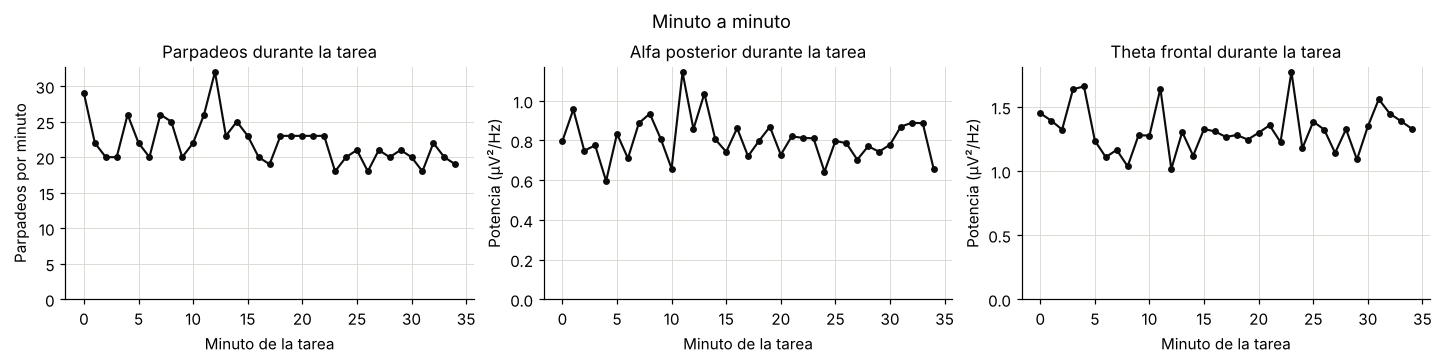

Línea base, antes: 5.3 min, 62 de 73 segmentos conservados, 13.0 parpadeos por minuto
Línea base, después: 5.3 min, 68 de 73 segmentos conservados, 10.8 parpadeos por minuto



Cambio de potencia entre la línea base inicial y la final:
        región banda  cambio (%)  IC95 inf  IC95 sup  p (Mann-Whitney)
Frontal medial theta        -9.5     -19.4       4.2            0.0522
Frontal medial  alfa       -21.9     -31.5     -10.1            0.0002
Frontal medial  beta        -3.0     -11.5       8.7            0.2467
       Central theta       -13.2     -23.6       0.7            0.0119
       Central  alfa       -26.7     -35.9     -10.1            0.0013
       Central  beta        -4.2     -12.6       4.6            0.1179
     Posterior theta        -3.7     -12.7       7.2            0.6163
     Posterior  alfa       -17.8     -29.1      -2.4            0.0201
     Posterior  beta        -7.2     -13.9       2.1            0.1401


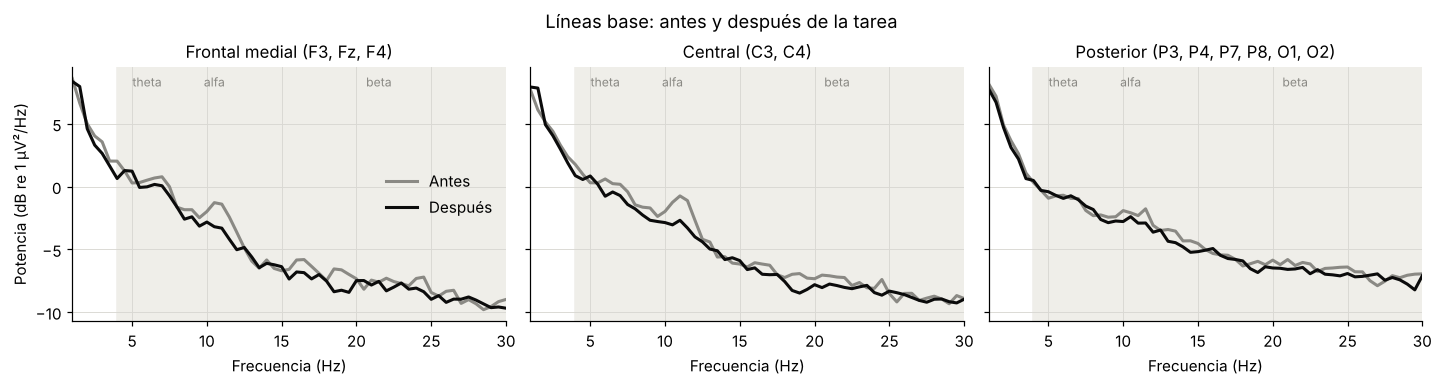

In [27]:
def clean_continuous(signal_uv_):
    """Señal continua de 1 a 40 Hz con la corrección ocular del ICA."""
    raw_ = mne.io.RawArray(signal_uv_.T * 1e-6, info.copy()).filter(1.0, 40.0, picks=CH_NAMES)
    return ica.apply(raw_) if ICA_ENABLED else raw_


def segment_psd(raw_, t0=None, t1=None, seg=4.0):
    """Espectro por segmento (segmentos × canales sanos × frecuencias) y número de segmentos conservados."""
    x = raw_.get_data(picks=GOOD_CHANNELS) * 1e6
    if t0 is not None:
        x = x[:, int(t0 * SFREQ):int(t1 * SFREQ)]
    n = int(seg * SFREQ)
    k = x.shape[1] // n
    x = x[:, :k * n].reshape(len(GOOD_CHANNELS), k, n).transpose(1, 0, 2)
    good_seg = np.ptp(x, axis=2).max(axis=1) < 100
    freqs_, psd_ = signal.welch(x[good_seg], fs=SFREQ, nperseg=n // 2, noverlap=n // 4, axis=-1)
    return freqs_, psd_, int(good_seg.sum()), int(k)


def blink_times(signal_uv_):
    """Instantes (s) de los parpadeos: picos del promedio de las referencias verticales, de 1 a 10 Hz."""
    idx = [CH_NAMES.index(c) for c in ICA_VEOG_PROXY]
    v = mne.filter.filter_data(signal_uv_[:, idx].mean(axis=1), SFREQ, 1.0, 10.0, verbose=False)
    peaks, _ = signal.find_peaks(v, height=80, distance=int(0.3 * SFREQ), prominence=60)
    return peaks / SFREQ


def band_power(psd_, freqs_, region, lo, hi):
    """Mediana entre segmentos de la potencia media de una región en una banda."""
    idx = [GOOD_CHANNELS.index(c) for c in FATIGUE_REGIONS[region] if c in GOOD_CHANNELS]
    return float(np.median(psd_[:, idx].mean(axis=1)[:, (freqs_ >= lo) & (freqs_ < hi)].mean(axis=1)))


per_minute, baseline_changes, baseline_spectra, blink_rate = pd.DataFrame(), pd.DataFrame(), {}, {}
if INPUT_KIND == "dat" and ICA_ENABLED:
    # ---- durante la tarea, minuto a minuto
    task_clean = clean_continuous(signal_uv)
    blinks = blink_times(signal_uv)
    duration = signal_uv.shape[0] / SFREQ
    blink_rate["tarea"] = len(blinks) / (duration / 60)
    rows = []
    for minute in range(int(duration // 60)):
        f_, p_, n_good, _ = segment_psd(task_clean, minute * 60, (minute + 1) * 60)
        if n_good < 4:
            continue
        rows.append({"minuto": minute, "alfa posterior": band_power(p_, f_, "Posterior", *FATIGUE_BANDS["alfa"]),
                     "theta frontal": band_power(p_, f_, "Frontal medial", *FATIGUE_BANDS["theta"]),
                     "parpadeos": int(((blinks >= minute * 60) & (blinks < (minute + 1) * 60)).sum())})
    per_minute = pd.DataFrame(rows)
    minute_trend = {c: stats.spearmanr(per_minute["minuto"], per_minute[c]) for c in ("parpadeos", "alfa posterior", "theta frontal")}
    for b in fatigue_blocks.index:
        idx = trials.index[trials["bloque"] == b]
        t0, t1 = onsets[idx[0]] / SFREQ, onsets[idx[-1]] / SFREQ + 6
        fatigue_blocks.loc[b, "parpadeos por minuto"] = ((blinks >= t0) & (blinks < t1)).sum() / ((t1 - t0) / 60)
    print("Parpadeos por minuto en cada bloque:", fatigue_blocks["parpadeos por minuto"].round(1).tolist())
    for c, r in minute_trend.items():
        print(f"Tendencia por minuto, {c}: ρ = {r.statistic:+.2f}, p = {r.pvalue:.3f}")

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), layout="constrained")
    for ax, (col, unit) in zip(axes, (("parpadeos", "Parpadeos por minuto"), ("alfa posterior", "Potencia (µV²/Hz)"), ("theta frontal", "Potencia (µV²/Hz)"))):
        ax.plot(per_minute["minuto"], per_minute[col], "o-", color=C_INK, ms=3.5, lw=1.4)
        ax.set(title=col.capitalize() + " durante la tarea", xlabel="Minuto de la tarea", ylabel=unit, ylim=(0, None))
    fig.suptitle(f"Minuto a minuto{DEMO_TAG}")
    save_fig(fig, "18_fatiga_por_minuto")
    plt.show()

    # ---- líneas base: antes contra después
    paths = {k: os.path.join(DATA_DIR, f) for k, f in BASELINE_FILES.items()}
    if all(os.path.exists(p) for p in paths.values()):
        rng_boot = np.random.default_rng(SEED)
        psd_runs = {}
        for when, path in paths.items():
            base_uv, _, _ = read_bci2000(path)
            dur = base_uv.shape[0] / SFREQ
            f_, p_, n_good, n_all = segment_psd(clean_continuous(base_uv), 10, dur - 10)      # sin los 10 s de cada extremo
            psd_runs[when] = (f_, p_)
            blink_rate[when] = len(blink_times(base_uv[int(10 * SFREQ):int((dur - 10) * SFREQ)])) / ((dur - 20) / 60)
            print(f"Línea base, {when}: {dur / 60:.1f} min, {n_good} de {n_all} segmentos conservados, "
                  f"{blink_rate[when]:.1f} parpadeos por minuto")
        f_ = psd_runs["antes"][0]
        fmask = (f_ >= 1) & (f_ <= 30)
        rows = []
        for region, chs in FATIGUE_REGIONS.items():
            idx = [GOOD_CHANNELS.index(c) for c in chs if c in GOOD_CHANNELS]
            pre = psd_runs["antes"][1][:, idx].mean(axis=1)[:, fmask]
            post = psd_runs["después"][1][:, idx].mean(axis=1)[:, fmask]
            baseline_spectra[region] = (10 * np.log10(np.median(pre, axis=0)), 10 * np.log10(np.median(post, axis=0)))
            for band, (lo, hi) in FATIGUE_BANDS.items():
                bmask = (f_[fmask] >= lo) & (f_[fmask] < hi)
                a, c = np.log10(pre[:, bmask].mean(axis=1)), np.log10(post[:, bmask].mean(axis=1))
                boot = [10 ** (np.median(rng_boot.choice(c, c.size)) - np.median(rng_boot.choice(a, a.size))) for _ in range(4000)]
                rows.append({"región": region, "banda": band, "cambio (%)": 100 * (10 ** (np.median(c) - np.median(a)) - 1),
                             "IC95 inf": 100 * (np.percentile(boot, 2.5) - 1), "IC95 sup": 100 * (np.percentile(boot, 97.5) - 1),
                             "p (Mann-Whitney)": stats.mannwhitneyu(a, c).pvalue})
        baseline_changes = pd.DataFrame(rows)
        baseline_changes.to_csv(os.path.join(OUT_DIR, f"{PARTICIPANT}_fatiga_lineas_base.csv"), index=False)
        print("\nCambio de potencia entre la línea base inicial y la final:")
        print(baseline_changes.round({"cambio (%)": 1, "IC95 inf": 1, "IC95 sup": 1, "p (Mann-Whitney)": 4}).to_string(index=False))

        fig, axes = plt.subplots(1, len(FATIGUE_REGIONS), figsize=(13, 3.4), sharey=True, layout="constrained")
        for ax, (region, (pre_db, post_db)) in zip(axes, baseline_spectra.items()):
            for band, (lo, hi) in FATIGUE_BANDS.items():
                ax.axvspan(lo, hi, color="#efeee9", zorder=0)
                ax.text((lo + hi) / 2, 0.97, band, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8, color=C_MUTED)
            ax.plot(f_[fmask], pre_db, color=C_MUTED, label="Antes")
            ax.plot(f_[fmask], post_db, color=C_INK, label="Después")
            ax.set(title=f"{region} ({', '.join(c for c in FATIGUE_REGIONS[region] if c in GOOD_CHANNELS)})", xlabel="Frecuencia (Hz)", xlim=(1, 30))
        axes[0].set_ylabel("Potencia (dB re 1 µV²/Hz)")
        axes[0].legend()
        fig.suptitle(f"Líneas base: antes y después de la tarea{DEMO_TAG}")
        save_fig(fig, "19_fatiga_lineas_base")
        plt.show()
    else:
        print("No encuentro las líneas base en DATA_DIR; se omite la comparación antes/después.")
else:
    print("Esta parte necesita el registro continuo (.dat) y el ICA; se omite.")

**Cómo leerlo.** Las señales clásicas de fatiga son respuestas más lentas o con más errores, una respuesta
parietal más pequeña, más potencia theta y alfa, y cambios en el parpadeo. Si en cambio el efecto Stroop se
reduce bloque a bloque con la exactitud estable, lo que se ve es aprendizaje: el conflicto cuesta cada vez menos.

## 14. Resumen de resultados
La celda siguiente redacta el resumen a partir de los números calculados arriba, de modo que el texto
siempre coincide con los datos analizados.

In [28]:
def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


lines = [f"RESUMEN — {PARTICIPANT}{DEMO_TAG}", "=" * 60,
         f"Archivo: {os.path.basename(data_path)} (modo {INPUT_KIND}). Canales excluidos: {', '.join(BAD_CHANNELS) or 'ninguno'}.",
         f"Ensayos analizados: {is_con.sum()} congruentes y {is_inc.sum()} incongruentes "
         f"(de {n_trials}; {100 * keep.mean():.0f} % conservado). Componentes ICA retirados: {len(ica_excluded)}.",
         "",
         "CONDUCTA"]
if HAS_ACCURACY:
    lines.append(f"  Exactitud: {behavior['Exactitud congruente (%)']:.1f} % (congruente) y "
                 f"{behavior['Exactitud incongruente (%)']:.1f} % (incongruente), {fmt_p(behavior['p (Fisher, exactitud)'])}.")
lines += [f"  RT mediano: {behavior['RT mediano congruente (ms)']:.0f} ms (congruente) y "
          f"{behavior['RT mediano incongruente (ms)']:.0f} ms (incongruente).",
          f"  Efecto Stroop: {behavior['Efecto Stroop, diferencia de medianas (ms)']:+.0f} ms, "
          f"{fmt_p(behavior['p (permutación)'])}, d = {behavior['d de Cohen sobre log(RT)']:.2f}.",
          "",
          "MOVIMIENTO OCULAR LIGADO A LA TAREA"]
for axis_name, span in gaze_summary.items():
    lines.append(f"  {axis_name}: sin desplazamiento sistemático." if span is None else
                 f"  {axis_name}: {span[2]:+.0f} µV, de ≈ {span[0] * 1000:.0f} a ≈ {span[1] * 1000:.0f} ms tras el estímulo.")
lines += ["", "ERP — amplitud media por ventana (Incongruente − Congruente, corregido por FDR)"]
significant = stats_table[stats_table["significativo (FDR)"]]
if significant.empty:
    lines.append("  Ninguna región × ventana sobrevive a la corrección.")
for _, r in significant.sort_values("p FDR").iterrows():
    lines.append(f"  {r['región']:<22s} {r['ventana']:<32s} {r['diferencia (µV)']:+.2f} µV, d = {r['d']:+.2f}, "
                 f"p FDR = {r['p FDR']:.3f}  [ocular retirado: {r['ocular retirado (µV)']:+.2f} µV]")
if not sensitivity_by_window.empty:
    lines += ["", "ERP — sensibilidad a la corrección ocular (mayor cambio entre variantes del ICA)"]
    for win_name, r in sensitivity_by_window.iterrows():
        lines.append(f"  {win_name:<32s} nivel: {r.iloc[0]:.2f} µV · diferencia: {r.iloc[1]:.2f} µV")
lines += ["", "ERP — clústeres temporales"]
if cluster_table.empty:
    lines.append("  Sin clústeres significativos.")
for _, r in cluster_table.iterrows():
    lines.append(f"  {r['región']:<22s} {r['inicio (ms)']:.0f}–{r['fin (ms)']:.0f} ms, {fmt_p(r['p'])}")
lines += ["", "LATERALIZACIÓN (interacción condición × hemisferio, FDR)"]
lat_sig = lateral_table[lateral_table["significativo (FDR)"]]
if lat_sig.empty:
    lines.append("  Sin evidencia de que el efecto difiera entre hemisferios.")
for _, r in lat_sig.iterrows():
    lines.append(f"  {r['par']:<22s} {r['ventana']:<32s} {r['interacción (µV)']:+.2f} µV, p FDR = {r['p FDR']:.3f}")
lines += ["", "FATIGA (exploratorio)",
          "  Efecto Stroop por bloque: " + ", ".join(f"{v:+.0f}" for v in fatigue_blocks["efecto Stroop (ms)"]) + " ms.",
          "  Respuesta parietal por bloque: " + ", ".join(f"{v:.1f}" for v in fatigue_blocks["respuesta parietal (µV)"]) + " µV."]
for name, tr_ in rt_trend.items():
    lines.append(f"  Tendencia del RT, {name.lower()}: ρ = {tr_['rho']:+.2f}, {fmt_p(tr_['p'])}.")
if not baseline_changes.empty:
    _alfa = baseline_changes[baseline_changes["banda"] == "alfa"]
    lines.append("  Alfa, línea base final frente a la inicial: " + ", ".join(f"{r['región'].lower()} {r['cambio (%)']:+.0f} %" for _, r in _alfa.iterrows()) + ".")
if blink_rate:
    lines.append("  Parpadeos por minuto: " + ", ".join(f"{k} {v:.1f}" for k, v in blink_rate.items()) + ".")
for ch, test in bad_channel_tests.items():
    lines.append(f"  {ch}: correlación de su amplitud con el RT, ρ = {test['rho_rt'][0]:+.2f}.")
lines += ["", "THETA FRONTAL MEDIAL (Fz)",
          f"  {theta_stats['diferencia (dB)']:+.2f} dB en incongruente, {fmt_p(theta_stats['p (permutación)'])}, "
          f"d = {theta_stats['d de Cohen']:.2f}."]
summary_text = "\n".join(lines)
with open(os.path.join(OUT_DIR, f"{PARTICIPANT}_resumen.txt"), "w", encoding="utf-8") as fh:
    fh.write(summary_text)
print(summary_text)

RESUMEN — P20
Archivo: P20_UTBS001R02.dat (modo dat). Canales excluidos: Pz.
Ensayos analizados: 158 congruentes y 149 incongruentes (de 320; 96 % conservado). Componentes ICA retirados: 3.

CONDUCTA
  Exactitud: 99.4 % (congruente) y 96.9 % (incongruente), p = 0.214.
  RT mediano: 977 ms (congruente) y 1047 ms (incongruente).
  Efecto Stroop: +70 ms, p < 0.001, d = 0.47.

MOVIMIENTO OCULAR LIGADO A LA TAREA
  Vertical: -84 µV, de ≈ 590 a ≈ 922 ms tras el estímulo.
  Horizontal: +101 µV, de ≈ 469 a ≈ 914 ms tras el estímulo.

ERP — amplitud media por ventana (Incongruente − Congruente, corregido por FDR)
  Ninguna región × ventana sobrevive a la corrección.

ERP — sensibilidad a la corrección ocular (mayor cambio entre variantes del ICA)
  Visual temprano (100–200 ms)     nivel: 0.63 µV · diferencia: 0.35 µV
  Conflicto N450/P3 (350–500 ms)   nivel: 2.81 µV · diferencia: 0.72 µV
  SP tardío (600–900 ms)           nivel: 6.57 µV · diferencia: 0.59 µV

ERP — clústeres temporales
  Sin cl

### Cómo interpretar el resumen
- **Conducta primero.** Un efecto Stroop claro en el RT confirma que la manipulación funcionó.
- **Movimiento ocular.** Si hay un desplazamiento sistemático de la mirada, todo efecto posterior a su
  inicio compite con una explicación ocular. Un resultado es más creíble cuanto menor sea su valor de
  "ocular retirado" frente a la diferencia reportada, y si aparece en regiones alejadas de los ojos.
- **Control negativo.** La ventana visual temprana en las regiones posteriores no debería diferir entre
  condiciones. Si difiere, sospecha de diferencias físicas entre estímulos o de artefactos residuales.
- **N450.** Diferencia *negativa* en la ventana de conflicto en regiones frontales, sobre todo en Fz.
- **SP de conflicto.** Diferencia *positiva* en la ventana tardía en regiones parietales y posteriores.
- **Theta.** Mayor potencia en Fz para incongruente, con topografía frontal medial.

### Limitaciones
1. **Un participante.** La inferencia es sobre los ensayos de esta persona. El siguiente paso es ejecutar
   este notebook para cada participante y hacer la estadística de grupo sobre los promedios individuales.
2. **Sin registro ocular.** Las referencias oculares se derivan del propio EEG frontal. Con canales EOG
   reales, o con seguimiento ocular, la corrección y su verificación serían mucho más sólidas.
3. **Latencias respecto al estímulo, no a la fijación.** Si el participante mueve los ojos durante el
   ensayo, las ventanas clásicas de la literatura (medidas con fijación central) son solo una aproximación.
4. **16 canales y sin Cz/FCz.** La N450 suele ser máxima en FCz/Cz, que este montaje no tiene; Fz es el
   mejor sustituto disponible. La resolución espacial solo permite hablar de regiones amplias.
5. **Referencia.** Las amplitudes y topografías dependen del electrodo de referencia del registro.
6. **Con el `.mat`** se pierden la exactitud de las respuestas y el filtrado sobre señal continua.

### Recomendaciones para futuros registros
- **Añadir electrooculograma** (dos electrodos junto a los ojos bastan) o seguimiento ocular.
- **Responder sin mirar**: botones en el volante o teclas que se localicen al tacto, con práctica previa.
  Así desaparece el desplazamiento de la mirada, que es el mayor obstáculo de este registro.
- **Revisar la impedancia a mitad de sesión**, para detectar a tiempo un electrodo que se degrada.
- **Incluir Cz o FCz** en el montaje si el interés es el conflicto (N450, theta medial).

### Referencias
- Cavanagh, J. F., & Frank, M. J. (2014). Frontal theta as a mechanism for cognitive control. *Trends in Cognitive Sciences, 18*(8), 414–421.
- Gramfort, A., et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience, 7*, 267.
- Larson, M. J., Clayson, P. E., & Clawson, A. (2014). Making sense of all the conflict: A theoretical review and critique of conflict-related ERPs. *International Journal of Psychophysiology, 93*(3), 283–297.
- Luck, S. J. (2014). *An Introduction to the Event-Related Potential Technique* (2.ª ed.). MIT Press.
- Maris, E., & Oostenveld, R. (2007). Nonparametric statistical testing of EEG- and MEG-data. *Journal of Neuroscience Methods, 164*(1), 177–190.
- Schalk, G., McFarland, D. J., Hinterberger, T., Birbaumer, N., & Wolpaw, J. R. (2004). BCI2000: A general-purpose brain-computer interface (BCI) system. *IEEE Transactions on Biomedical Engineering, 51*(6), 1034–1043.
- Tanner, D., Morgan-Short, K., & Luck, S. J. (2015). How inappropriate high-pass filters can produce artifactual effects and incorrect conclusions in ERP studies of language and cognition. *Psychophysiology, 52*(8), 997–1009.